# Monthly Sales Forecast - November 2015

**Table of contents**

- [1. Problem Framing & Data Understanding](#1.-Problem-Framing-&-Data-Understanding)
  - [1.1 Framing](#1.1-Framing)
  - [1.2 Data overview](#1.2-Data-overview)
  - [1.3 Data-quality audit](#1.3-Data-quality-audit)
- [2. Exploratory Data Analysis](#2.-Exploratory-Data-Analysis)
  - [2.1 Univariate distributions](#2.1-Univariate-distributions)
  - [2.2 Temporal patterns](#2.2-Temporal-patterns)
  - [2.3 Entity-level concentration](#2.3-Entity-level-concentration)
  - [2.4 Test-set profiling](#2.4-Test-set-profiling)
- [3. Deep-dive Analysis](#3.-Deep-dive-Analysis)
  - [3.1 Trend & seasonality](#3.1-Trend-&-seasonality)
  - [3.2 Shop lifecycle & duplicated shops](#3.2-Shop-lifecycle-&-duplicated-shops)
  - [3.3 Product lifecycle](#3.3-Product-lifecycle)
  - [3.4 Sparsity & persistence on the monthly grid](#3.4-Sparsity-&-persistence-on-the-monthly-grid)
  - [3.5 Autocorrelation - which lags matter?](#3.5-Autocorrelation---which-lags-matter?)
  - [3.6 Price analysis](#3.6-Price-analysis)
  - [3.7 Cold start - brand-new items](#3.7-Cold-start---brand-new-items)
  - [3.8 Spikes and high-volume items](#3.8-Spikes-and-high-volume-items)
  - [3.9 Analysis summary](#3.9-Analysis-summary)
- [4. Data Processing & Feature Engineering](#4.-Data-Processing-&-Feature-Engineering)
  - [4.1 Feature construction](#4.1-Feature-construction)
- [5. Modeling](#5.-Modeling)
  - [5.1 Metric strategy](#5.1-Metric-strategy)
  - [5.2 Validation design](#5.2-Validation-design)
  - [5.3 Baselines](#5.3-Baselines)
  - [5.4 Loss function / target treatment](#5.4-Loss-function-/-target-treatment)
  - [5.5 Grid vs. transactions-only training](#5.5-Grid-vs.-transactions-only-training)
  - [5.6 Feature-group ablation](#5.6-Feature-group-ablation)
  - [5.7 Hyper-parameter selection](#5.7-Hyper-parameter-selection)
- [6. Evaluation & Error Analysis](#6.-Evaluation-&-Error-Analysis)
  - [6.1 Backtest of the final model](#6.1-Backtest-of-the-final-model)
  - [6.2 Performance by segment (fold 33)](#6.2-Performance-by-segment-(fold-33))
  - [6.3 Error by category and largest misses](#6.3-Error-by-category-and-largest-misses)
  - [6.4 Interpretability - feature importance and SHAP](#6.4-Interpretability---feature-importance-and-SHAP)
  - [6.5 Uncertainty - prediction intervals for item totals](#6.5-Uncertainty---prediction-intervals-for-item-totals)
- [7. Final Forecast & Artifacts](#7.-Final-Forecast-&-Artifacts)
- [8. Conclusion & Next Steps](#8.-Conclusion-&-Next-Steps)

## 1. Problem Framing & Data Understanding

### 1.1 Framing

- Mục tiêu: dự báo tổng số lượng bán theo tháng (net, tính cả hàng trả lại) cho từng cặp `(shop_id, item_id)`
- Horizon 1 tháng; input là giao dịch theo ngày -> cần aggregate lên tháng
- Người dùng cuối xem dự báo theo item trên web -> dự báo phải cộng dồn tốt qua các shop
- Đề không bắt buộc định nghĩa về metric -> cần tự định nghĩa sau khi EDA

### 1.2 Data overview

In [1]:
import os, time, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import lightgbm as lgb
from statsmodels.tsa.seasonal import STL

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
pd.set_option('display.max_columns', 50)
NB_START = time.time()

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
RAW, ART = ROOT / 'data' / 'raw', ROOT / 'artifacts'
ART.mkdir(exist_ok=True)
SEED = 42
FAST = os.getenv('NB_FAST') == '1'  # smoke-test mode for CI: tiny models, same code path

# Plot style: validated categorical palette (fixed order), thin marks, recessive grid, single y-axis per chart.
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
BLUE_RAMP = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']
SEQ = mcolors.LinearSegmentedColormap.from_list('seq_blue', BLUE_RAMP)
GRAY = '#8a8984'
plt.rcParams.update({
    'axes.prop_cycle': plt.cycler(color=PALETTE), 'figure.dpi': 110, 'savefig.dpi': 110,
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#b5b4ae',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e5e1',
    'grid.linewidth': 0.6, 'lines.linewidth': 2, 'font.size': 9.5, 'axes.titlesize': 10.5,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'legend.frameon': False,
})

# ---- Reusable chart helpers
def month_label(block):
    """date_block_num -> 'YYYY-MM' (0 = 2013-01)."""
    return str(pd.Period('2013-01', 'M') + int(block))

def fmt_month_axis(ax, interval=3):
    """Date x-axis with one tick every `interval` months, YYYY-MM labels rotated so they never overlap."""
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1, 13, interval)))  # ticks on Jan / Apr / Jul / Oct
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

def line_chart(ax, x, series, title, xlabel=None, ylabel=None, marker=None):
    """One line per entry of `series` (label -> values), colors in fixed palette order; legend only for 2+ lines."""
    for i, (label, y) in enumerate(series.items()):
        ax.plot(x, y, color=PALETTE[i], marker=marker, markersize=4, label=label)
    ax.set_title(title)
    ax.set_xlabel(xlabel or ''); ax.set_ylabel(ylabel or '')
    if len(series) > 1:
        ax.legend(fontsize=8)
    return ax

def bar_chart(ax, x, y, title, colors=None, width=0.8, label=None, xlabel=None, ylabel=None):
    ax.bar(x, y, width=width, color=PALETTE[0] if colors is None else colors, label=label)
    ax.set_title(title)
    ax.set_xlabel(xlabel or ''); ax.set_ylabel(ylabel or '')
    return ax

def hist_chart(ax, values, bins, title, xlabel=None, ylabel='rows', log_y=False):
    ax.hist(values, bins=bins, color=PALETTE[0], edgecolor='#fcfcfb', linewidth=0.5)
    if log_y:
        ax.set_yscale('log')
    ax.set_title(title)
    ax.set_xlabel(xlabel or ''); ax.set_ylabel(ylabel or '')
    return ax

def heatmap(ax, values, title, cbar_label, yticklabels, xticklabels, xtick_every=3, xlabel=None, ylabel=None):
    """Sequential heatmap; cells <= 0 stay blank; thin white lines separate the cells."""
    values = np.asarray(values, dtype=float)
    cmap = SEQ.copy(); cmap.set_bad('#fcfcfb')
    im = ax.imshow(np.ma.masked_less_equal(values, 0), aspect='auto', cmap=cmap, interpolation='nearest')
    ax.set_yticks(range(values.shape[0])); ax.set_yticklabels(yticklabels, fontsize=6.5)
    ticks = list(range(0, values.shape[1], xtick_every))
    ax.set_xticks(ticks); ax.set_xticklabels([xticklabels[t] for t in ticks], fontsize=8)
    # Minor ticks on cell borders -> white grid lines between cells
    ax.set_xticks(np.arange(-0.5, values.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, values.shape[0], 1), minor=True)
    ax.grid(False, which='major')
    ax.grid(True, which='minor', color='white', linewidth=0.8)
    ax.tick_params(which='minor', length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title); ax.set_xlabel(xlabel or ''); ax.set_ylabel(ylabel or '')
    plt.colorbar(im, ax=ax, label=cbar_label, shrink=0.6)
    return ax

def fold_timeline(ax, folds, first_train, forecast_month=34):
    """One row per fold: gray = lag history only, blue = training months, orange = validation / forecast month."""
    rows = [(f'Fold {v}: validate {month_label(v)}', v) for v in folds] + [(f'Final: forecast {month_label(forecast_month)}', forecast_month)]
    for r, (_, v) in enumerate(rows):
        for m in range(v + 1):
            color = '#d9d8d3' if m < first_train else (PALETTE[1] if m == v else PALETTE[0])
            ax.barh(r, 1, left=m - 0.5, height=0.6, color=color, edgecolor='#fcfcfb', linewidth=1)
    ax.set_yticks(range(len(rows))); ax.set_yticklabels([label for label, _ in rows]); ax.invert_yaxis()
    ticks = list(range(0, forecast_month + 1, 3))
    ax.set_xticks(ticks); ax.set_xticklabels([f'{month_label(t)}\n({t})' for t in ticks], fontsize=8)
    ax.set_xlim(-0.6, forecast_month + 0.6); ax.grid(False)
    ax.legend(handles=[Patch(color='#d9d8d3', label='lag history only'), Patch(color=PALETTE[0], label='train'),
                       Patch(color=PALETTE[1], label='validate / forecast')], loc='lower right', bbox_to_anchor=(1, 1.0), fontsize=8, ncol=3)
    return ax

In [2]:
train_raw = pd.read_csv(RAW / 'train.csv', index_col=0)
test_raw = pd.read_csv(RAW / 'test.csv')
items = pd.read_csv(RAW / 'items.csv')
shops = pd.read_csv(RAW / 'shops.csv')
cats = pd.read_csv(RAW / 'item_categories.csv')

overview = pd.DataFrame({
    name: {'rows': len(d), 'columns': ', '.join(d.columns), 'nulls': int(d.isna().sum().sum()),
           'duplicate rows': int(d.duplicated().sum())}
    for name, d in [('train', train_raw), ('test', test_raw), ('items', items), ('shops', shops), ('item_categories', cats)]
}).T
overview

,rows,columns,nulls,duplicate rows
train,2935849,"date, date_block_num, shop_id, item_id, item_p...",0,6
test,214200,"ID, shop_id, item_id",0,0
items,22170,"item_id, item_category_id",0,0
shops,60,shop_id,0,0
item_categories,84,item_category_id,0,0


- train: có khoảng 2.94M dòng giao dịch gồm nhiều thông tin, có thời gian
- test: 214,200 dòng chỉ gồm `ID, shop_id, item_id` (không có ngày/date)
- `items`, `shops`, `item_categories` chỉ có ID - không có cột tên như trong assignment document
- Không có null; train có 6 dòng trùng hoàn toàn
- `date_block_num` là số thứ tự tháng: 0 = 2013-01, 12 = 2014-01, 33 = 2015-10, 34 = 2015-11 (tháng cần dự báo)

### 1.3 Data-quality audit

In [3]:
dates = pd.to_datetime(train_raw['date'], format='%d.%m.%Y', errors='coerce')

tr0 = train_raw.assign(date=dates)
audit = pd.Series({
    'exact duplicate rows': tr0.duplicated().sum(),
    'duplicate (date, shop, item) keys': tr0.duplicated(['date', 'shop_id', 'item_id']).sum(),
    'item_cnt_day < 0 (returns?)': (tr0.item_cnt_day < 0).sum(),
    'item_cnt_day non-integer': (tr0.item_cnt_day % 1 != 0).sum(),
    'item_price <= 0': (tr0.item_price <= 0).sum(),
    'item_price > 100,000': (tr0.item_price > 100_000).sum(),
    'item_cnt_day >= 1,000': (tr0.item_cnt_day >= 1000).sum(),
    'train items missing from items.csv': (~tr0.item_id.isin(items.item_id)).sum(),
    'test items missing from items.csv': (~test_raw.item_id.isin(items.item_id)).sum(),
    'test duplicate (shop, item) pairs': test_raw.duplicated(['shop_id', 'item_id']).sum(),
}, name='count').to_frame()
audit

,count
exact duplicate rows,6
"duplicate (date, shop, item) keys",28
item_cnt_day < 0 (returns?),7356
item_cnt_day non-integer,0
item_price <= 0,1
"item_price > 100,000",1
"item_cnt_day >= 1,000",2
train items missing from items.csv,0
test items missing from items.csv,0
"test duplicate (shop, item) pairs",0


- 7,356 dòng `item_cnt_day < 0` -> hàng trả lại; giữ lại dùng để tính net sales
- 1 dòng giá ≤ 0, 1 dòng giá > 100k, 2 dòng ≥ 1,000 units/ngày -> cần EDA kỹ hơn trước khi chọn phương án xử lý
- 6 dòng trùng hoàn toàn, 28 key `(date, shop, item)` bị lặp
- Không item nào trong train/test thiếu trong `items.csv`; test không có cặp trùng

## 2. Exploratory Data Analysis

### 2.1 Univariate distributions

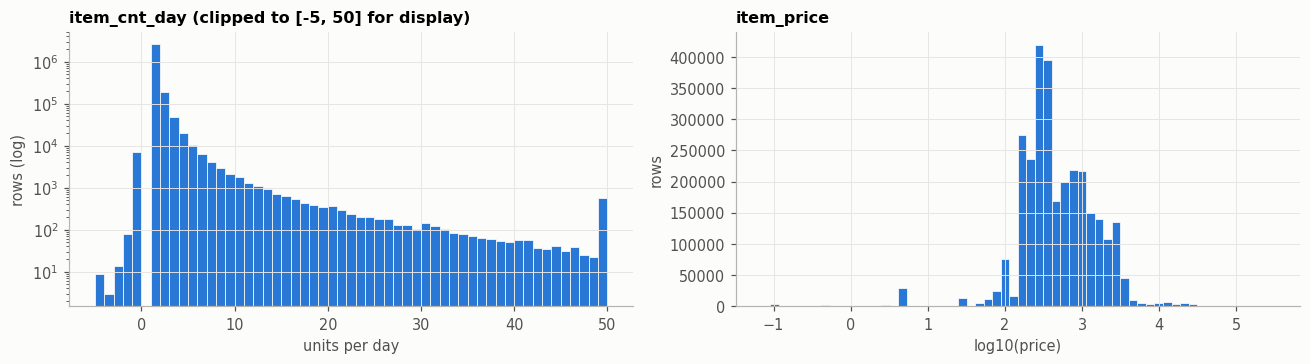

item_cnt_day quantiles: {0.5: 1.0, 0.9: 2.0, 0.99: 5.0, 0.999: 22.0}  max=2169
item_price  quantiles: {0.5: 399.0, 0.9: 1999.0, 0.99: 5999.0, 0.999: 23990.0}  max=307,980


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
c = tr0.item_cnt_day
p = tr0.item_price[tr0.item_price > 0]
hist_chart(ax[0], c.clip(-5, 50), 55, 'item_cnt_day (clipped to [-5, 50] for display)', xlabel='units per day', ylabel='rows (log)', log_y=True)
hist_chart(ax[1], np.log10(p), 60, 'item_price', xlabel='log10(price)')
plt.tight_layout(); plt.show()
print(f"item_cnt_day quantiles: {c.quantile([.5, .9, .99, .999]).to_dict()}  max={c.max():.0f}")
print(f"item_price  quantiles: {p.quantile([.5, .9, .99, .999]).round(0).to_dict()}  max={p.max():,.0f}")

- `item_cnt_day`: median 1, 99% ≤ 5, 99.9% ≤ 22, nhưng max = 2,169 -> đây là distribution có phần đuôi cực dài
- `item_price`: median 399, p99.9 = 23,990, max 307,980 -> trải nhiều bậc giá khác nhau, có outlier


In [5]:
# Inspect each extreme case in context instead of applying a blind threshold.
def item_context(item_id):
    s = tr0[tr0.item_id == item_id]
    return {'item_id': item_id, 'category': int(s.item_category_id.iloc[0]), 'rows': len(s),
            'median units/day': s.item_cnt_day.median(), 'max units/day': s.item_cnt_day.max(),
            'n shops': s.shop_id.nunique(), 'median price': s.item_price.median(), 'max price': s.item_price.max()}

extreme_ids = list(tr0.nlargest(3, 'item_cnt_day').item_id) + list(tr0.nlargest(2, 'item_price').item_id)
pd.DataFrame([item_context(i) for i in dict.fromkeys(extreme_ids)])

,item_id,category,rows,median units/day,max units/day,n shops,median price,max price
0,11373,9,464,4.0000,"2,169.0000",1,281.6250,"2,137.0000"
1,20949,71,31340,3.0000,"1,000.0000",53,5.0000,5.0000
2,9248,80,61,2.0000,669.0000,2,"1,500.0000","1,692.5262"
3,6066,75,1,1.0000,1.0000,1,"307,980.0000","307,980.0000"
4,11365,9,242,2.0000,103.0000,1,"1,203.7500","59,200.0000"


- Item 11373 (1 shop) thường bán khoảng 4 units/ngày -> ngày 2,169 units là spike
- Item 20949 bán ở 53 shop, khoảng 3 units/ngày -> item high-volume thật; chỉ riêng ngày 1,000 units là bất thường
- Item 6066 (giá 307,980) chỉ bán đúng 1 lần
-> CÓ thể bỏ các dòng theo ngày ≥ 1,000 units và dòng giá > 100k; giữ lại bản thân các item

### 2.2 Temporal patterns

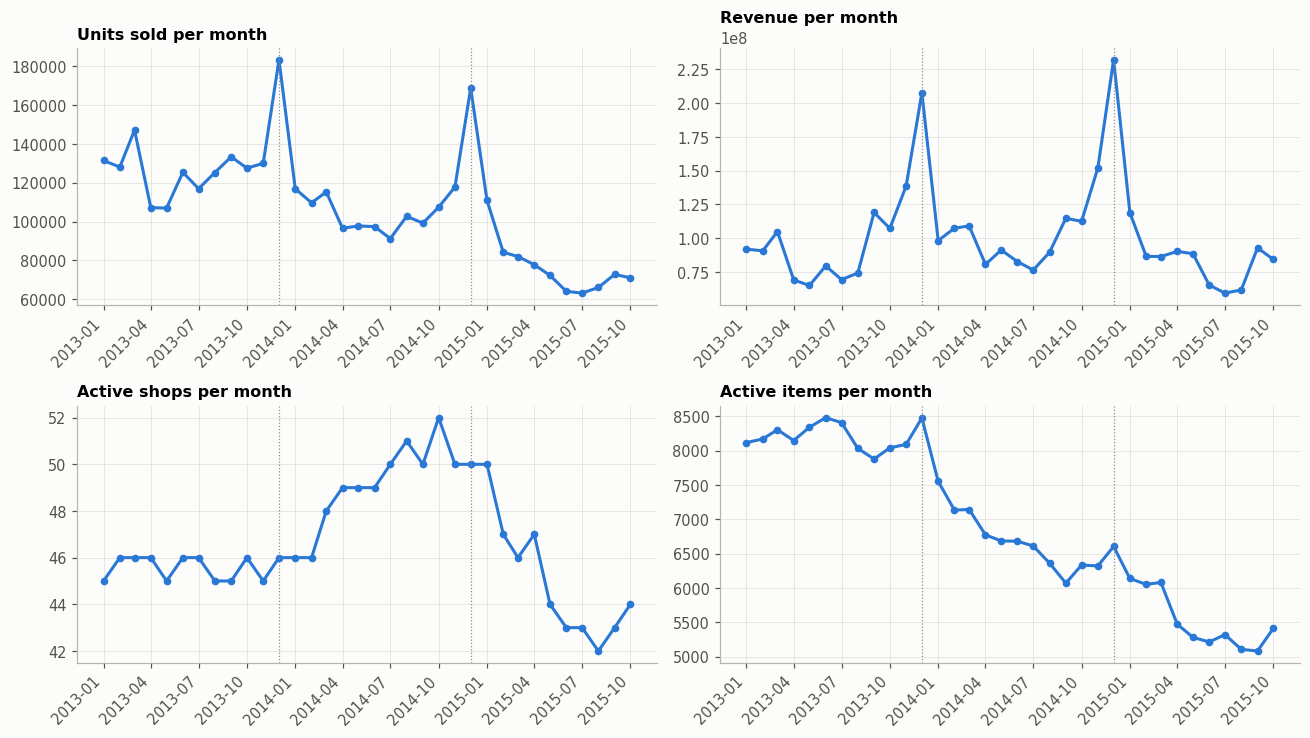

Average units per calendar day by weekday:
{'Monday': 2731.0, 'Tuesday': 3074.0, 'Wednesday': 2971.0, 'Thursday': 3072.0, 'Friday': 3740.0, 'Saturday': 4964.0, 'Sunday': 4145.0}


In [6]:
tr0['revenue'] = tr0.item_price * tr0.item_cnt_day
monthly = tr0.groupby('date_block_num').agg(units=('item_cnt_day', 'sum'), revenue=('revenue', 'sum'),
                                             shops=('shop_id', 'nunique'), items=('item_id', 'nunique'))
monthly.index = pd.period_range('2013-01', periods=34, freq='M')

x = monthly.index.to_timestamp()
fig, ax = plt.subplots(2, 2, figsize=(12, 6.8))
for a, col, title in [(ax[0, 0], 'units', 'Units sold per month'), (ax[0, 1], 'revenue', 'Revenue per month'),
                      (ax[1, 0], 'shops', 'Active shops per month'), (ax[1, 1], 'items', 'Active items per month')]:
    line_chart(a, x, {col: monthly[col]}, title, marker='o')
    # Dotted line on every December to make the yearly peak visible
    for d in x[x.month == 12]:
        a.axvline(d, color=GRAY, lw=0.8, ls=':')
    fmt_month_axis(a)
plt.tight_layout(); plt.show()

# Average units per calendar day, by weekday (sum of units / number of such days)
dow = tr0.groupby(tr0.date.dt.day_name()).item_cnt_day.sum() / tr0.groupby(tr0.date.dt.day_name()).date.nunique()
print('Average units per calendar day by weekday:')
print(dow.reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']).round(0).to_dict())

- Units có xu hướng chung là giảm đều: từ khoảng 130k/tháng (2013) về khoảng 70k/tháng (2015)
- Đỉnh rõ vào tháng 12 mỗi năm (đường chấm) -> có seasonality
- Revenue giảm chậm hơn units -> khả năng giá trung bình mỗi unit tăng
- Số item active giảm, số shop tương đối ổn định
- Thứ 7 / Chủ nhật bán nhiều hơn ngày thường khoảng 1.5 lần
-> Cần có feature trend (lag gần) và month-of-year

### 2.3 Entity-level concentration

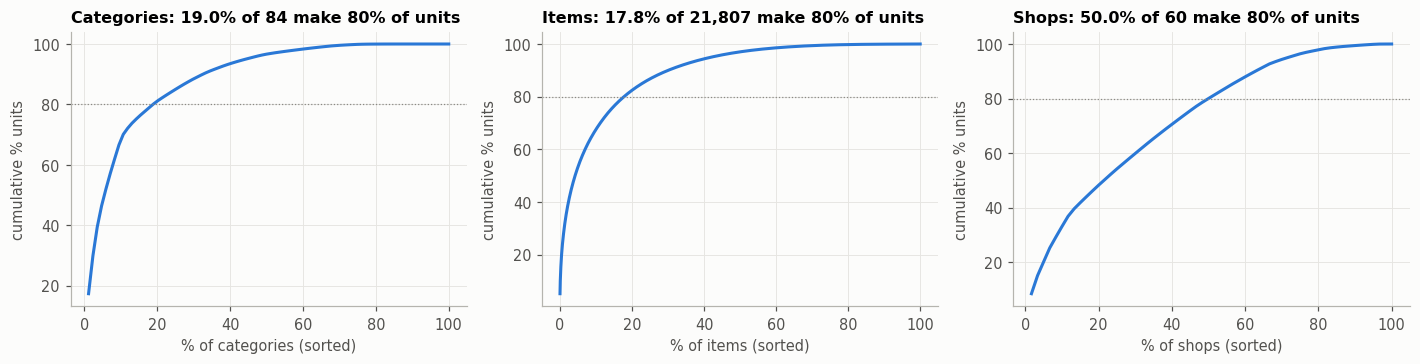

In [7]:
cat_units = tr0.groupby('item_category_id').item_cnt_day.sum().sort_values(ascending=False)
item_units = tr0.groupby('item_id').item_cnt_day.sum().sort_values(ascending=False)
shop_units = tr0.groupby('shop_id').item_cnt_day.sum().sort_values(ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, s, title in [(ax[0], cat_units, 'Categories'), (ax[1], item_units, 'Items'), (ax[2], shop_units, 'Shops')]:
    # Cumulative share of units after sorting entities from largest to smallest (Pareto curve)
    share = s.clip(lower=0).cumsum() / s.clip(lower=0).sum()
    n80 = (share < 0.8).sum() + 1
    line_chart(a, np.arange(1, len(s) + 1) / len(s) * 100, {title: share * 100},
               f'{title}: {n80 / len(s):.1%} of {len(s):,} make 80% of units',
               xlabel=f'% of {title.lower()} (sorted)', ylabel='cumulative % units')
    a.axhline(80, color=GRAY, lw=0.8, ls=':')
plt.tight_layout(); plt.show()

- Một phần rất nhỏ item và category chiếm phần lớn volume (Pareto) -> long tail các item bán chậm
- Quy mô shop chênh nhau lớn
- -> Cân nhắc target encoding theo item, shop, category, shop×category sẽ có giá trị

### 2.4 Test-set profiling

In [8]:
pairs_hist = set(zip(tr0.shop_id, tr0.item_id))
items_hist = set(tr0.item_id)
tp = test_raw.merge(items, on='item_id')
# Segment each test pair by the history available: the pair itself (A), only the item (B), nothing (C)
tp['segment'] = np.select(
    [[p in pairs_hist for p in zip(tp.shop_id, tp.item_id)], tp.item_id.isin(items_hist)],
    ['A: pair has history', 'B: known item, new pair'], 'C: brand-new item')
print(f"test rows: {len(tp):,} = {tp.shop_id.nunique()} shops × {tp.item_id.nunique():,} items "
      f"-> full Cartesian grid: {len(tp) == tp.shop_id.nunique() * tp.item_id.nunique()}")
seg = tp.groupby('segment').agg(rows=('ID', 'size'), items=('item_id', 'nunique'))
seg['share of rows'] = seg.rows / seg.rows.sum()
seg

test rows: 214,200 = 42 shops × 5,100 items -> full Cartesian grid: True


,rows,items,share of rows
segment,,,
A: pair has history,111404,4716,0.5201
"B: known item, new pair",87550,4737,0.4087
C: brand-new item,15246,363,0.0712


- Test là Cartesian grid: 42 shops × 5,100 items
- A - cặp đã có lịch sử: 52% dòng
- B - item đã biết nhưng chưa bán ở shop đó: 41% dòng
- C - item hoàn toàn mới: 363 items, 7% dòng
- -> Gần một nửa bộ test là cặp chưa từng có giao dịch

In [9]:
last = tr0[tr0.date_block_num == 33].groupby(['shop_id', 'item_id']).item_cnt_day.sum().rename('oct_units').reset_index()
proj = test_raw.merge(last, how='left', on=['shop_id', 'item_id']).fillna({'oct_units': 0})
print(f"If Oct-2015 sales are projected onto the test grid: mean = {proj.oct_units.clip(0).mean():.3f}, "
      f"share of zeros = {(proj.oct_units <= 0).mean():.1%}")
print('Shops in train but not in test (closed/merged):', sorted(set(tr0.shop_id) - set(test_raw.shop_id)))
print('Category mix of brand-new items (top 5):', tp[tp.segment.str.startswith('C')].drop_duplicates('item_id').item_category_id.value_counts().head(5).to_dict())

If Oct-2015 sales are projected onto the test grid: mean = 0.293, share of zeros = 86.6%
Shops in train but not in test (closed/merged): [0, 1, 8, 9, 11, 13, 17, 20, 23, 27, 29, 30, 32, 33, 40, 43, 51, 54]
Category mix of brand-new items (top 5): {40: 71, 55: 38, 72: 28, 31: 25, 47: 22}


- Chiếu doanh số tháng 10 lên test grid: mean 0.29, **86.6% bằng 0** -> target zero-inflated. Nhiều cặp shop-item = 0
- 18 shop có trong train nhưng không có trong test
- Item mới tập trung ở vài category (40, 55, 72, 31, 47)
- -> Phải train trên grid xây giống test, không chỉ trên dòng có giao dịch
- -> Theo dõi 3 segment A/B/C trong mọi bước đánh giá; cần chiến lược cold-start

## 3. Deep-dive Analysis

### 3.1 Trend & seasonality

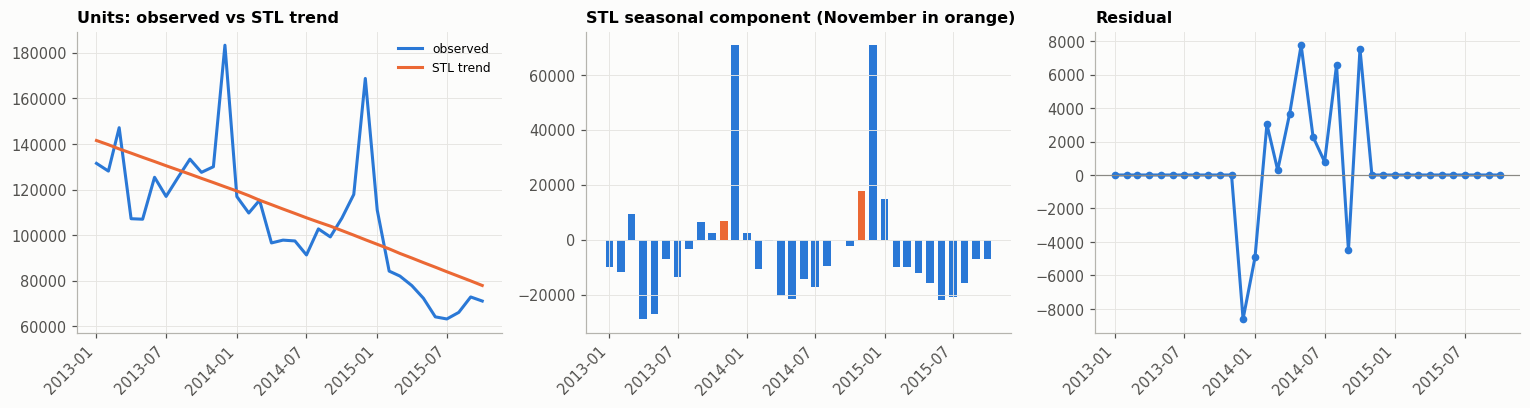

Nov/Oct units ratio: {2013: np.float64(1.019), 2014: np.float64(1.097)} | Jan-Oct 2015 vs Jan-Oct 2014: -26.1%


In [10]:
stl = STL(monthly.units.values, period=12, robust=True).fit()
x = monthly.index.to_timestamp()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
line_chart(ax[0], x, {'observed': monthly.units, 'STL trend': stl.trend}, 'Units: observed vs STL trend')
bar_chart(ax[1], x, stl.seasonal, 'STL seasonal component (November in orange)', width=20,
          colors=[PALETTE[1] if d.month == 11 else PALETTE[0] for d in x])
line_chart(ax[2], x, {'residual': stl.resid}, 'Residual', marker='o')
ax[2].axhline(0, color=GRAY, lw=0.8)
for a in ax:
    fmt_month_axis(a, interval=6)
plt.tight_layout(); plt.show()

nov_oct = {2013: monthly.units.iloc[10] / monthly.units.iloc[9], 2014: monthly.units.iloc[22] / monthly.units.iloc[21]}
yoy = monthly.units.iloc[24:34].sum() / monthly.units.iloc[12:22].sum() - 1
print('Nov/Oct units ratio:', {k: round(v, 3) for k, v in nov_oct.items()}, f'| Jan-Oct 2015 vs Jan-Oct 2014: {yoy:+.1%}')

- Trend giảm mượt và đều
- Seasonal: tháng 12 tăng mạnh, **tháng 11 gần trung tính**
- Tỷ lệ tháng 11/tháng 10: 1.02 (2013), 1.10 (2014)
- tháng 1-10/2015 giảm 26% so với cùng kỳ 2014

In [11]:
# Where does the decline come from? Compare Jan–Oct 2015 vs Jan–Oct 2014 by category.
ytd = tr0[tr0.date_block_num.between(12, 21) | tr0.date_block_num.between(24, 33)].assign(
    year=lambda d: np.where(d.date_block_num >= 24, 2015, 2014))
cy = ytd.pivot_table(index='item_category_id', columns='year', values='item_cnt_day', aggfunc='sum').fillna(0)
cy['delta'] = cy[2015] - cy[2014]
cy['growth'] = cy[2015] / cy[2014].replace(0, np.nan) - 1
cy['share of total change'] = cy.delta / cy.delta.sum()
print(f"Total change: {cy.delta.sum():,.0f} units")
pd.concat([cy.nsmallest(5, 'delta'), cy.nlargest(3, 'delta')]).round(3)

Total change: -269,705 units


year,2014,2015,delta,growth,share of total change
item_category_id,,,,,
40,"167,847.0000","101,743.0000","-66,104.0000",-0.3940,0.2450
30,"124,106.0000","74,870.0000","-49,236.0000",-0.3970,0.1830
55,"101,104.0000","68,957.0000","-32,147.0000",-0.3180,0.1190
19,"65,854.0000","38,264.0000","-27,590.0000",-0.4190,0.1020
71,"65,382.0000","38,782.0000","-26,600.0000",-0.4070,0.0990
20,"43,562.0000","54,225.0000","10,663.0000",0.2450,-0.0400
24,"1,072.0000","11,429.0000","10,357.0000",9.6610,-0.0380
70,"8,742.0000","18,356.0000","9,614.0000",1.1000,-0.0360


- tháng 1-10/2015 giảm khoảng 270k units so với cùng kỳ 2014; 5 category (40, 30, 55, 19, 71) chiếm khoảng 76% mức giảm
- Category 20, 24, 70 tăng mạnh (category 24 tăng gần 10×)
- -> Trend khác nhau theo category -> nên dùng lagged category/item means
- -> Seasonal baseline: tháng trước × tỷ lệ tháng 11/tháng 10 của năm trước

### 3.2 Shop lifecycle & duplicated shops

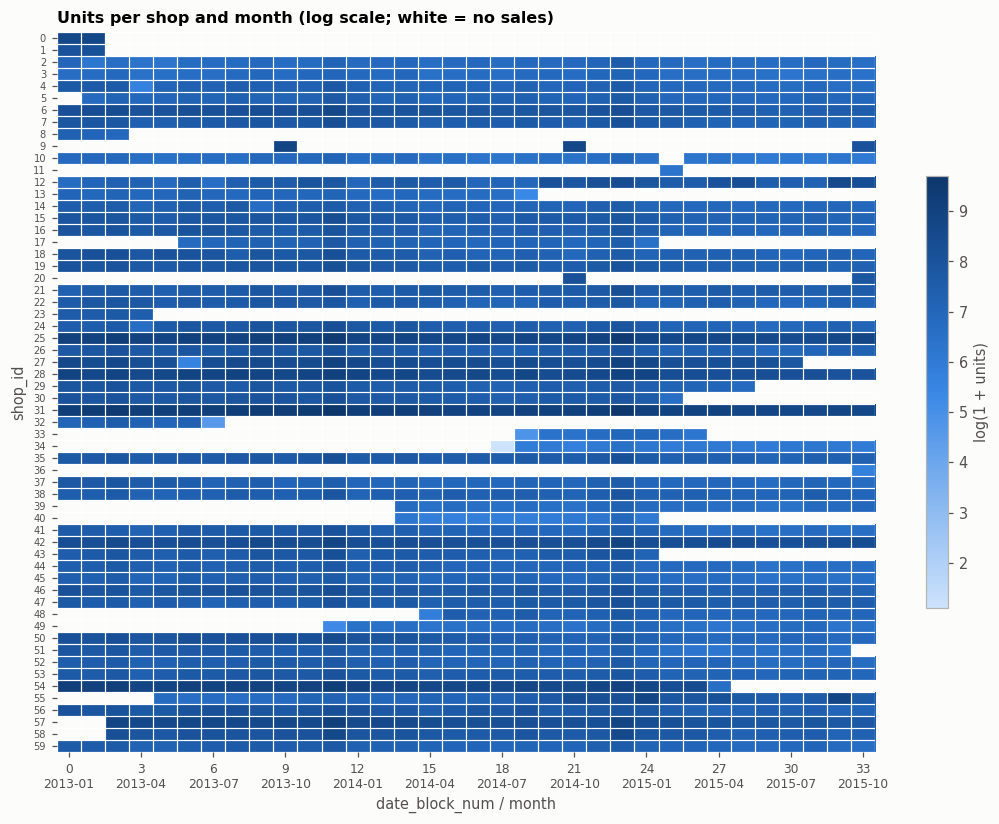

In [12]:
shop_month = tr0.groupby(['shop_id', 'date_block_num']).item_cnt_day.sum().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(12, 8.5))
heatmap(ax, np.log1p(shop_month.clip(lower=0)), 'Units per shop and month (log scale; white = no sales)', 'log(1 + units)',
        yticklabels=shop_month.index, xticklabels=[f'{b}\n{month_label(b)}' for b in shop_month.columns],
        xlabel='date_block_num / month', ylabel='shop_id')
plt.show()

- Shop 0, 1 chỉ bán tháng 0-1; shop 57, 58 bắt đầu đúng từ tháng 2
- Shop 11 chỉ bán tháng 25 - đúng tháng shop 10 bị trống
- Shop 36 chỉ xuất hiện ở tháng cuối; nhiều shop đóng cửa giữa chừng
- Vài shop (9, 20) chỉ hoạt động lẻ tẻ vài tháng
- -> Nghi ngờ có shop bị ghi dưới 2 ID -> cần kiểm tra

In [ ]:
def cat_mix(shop):
    s = tr0[tr0.shop_id == shop].groupby('item_category_id').item_cnt_day.sum().clip(lower=0)
    return s / s.sum()

def months_active(shop):
    m = sorted(tr0.loc[tr0.shop_id == shop, 'date_block_num'].unique())
    return f'{m[0]}–{m[-1]} ({len(m)} months)'

# Cosine similarity between shops' category mix (share of units per category)
mix = pd.DataFrame({s: cat_mix(s) for s in shop_month.index}).fillna(0)
sim = mix.T.dot(mix) / np.outer(np.linalg.norm(mix, axis=0), np.linalg.norm(mix, axis=0))
sim = pd.DataFrame(sim, index=mix.columns, columns=mix.columns)

# Candidate duplicate: a short-lived shop (<= 3 months) that never overlaps another shop in time and
# fills a gap in / extends contiguously the other shop's activity. Confirm with category mix and item overlap.
act = tr0.groupby('shop_id').date_block_num.apply(lambda s: set(s.unique()))
rows = []
for a in act.index:
    for b in act.index:
        A, Bm = act[a], act[b]
        if a == b or len(A) > 3 or len(A) >= len(Bm) or A & Bm:
            continue
        U = A | Bm
        if max(U) - min(U) + 1 != len(U):
            continue
        # Item overlap is measured against the target shop's 3 months closest to the candidate's activity
        near = sorted(Bm, key=lambda m: min(abs(m - x) for x in A))[:3]
        ib = set(tr0.loc[(tr0.shop_id == b) & tr0.date_block_num.isin(near), 'item_id'])
        ia = set(tr0.loc[tr0.shop_id == a, 'item_id'])
        rows.append({'candidate': a, 'target': b, 'candidate months': sorted(int(m) for m in A), 'target active': months_active(b),
                     'category-mix cosine': sim.loc[a, b], 'item Jaccard (adjacent months)': len(ia & ib) / len(ia | ib)})
cand = pd.DataFrame(rows)
cand['accepted'] = (cand['category-mix cosine'] >= 0.9) & (cand['item Jaccard (adjacent months)'] >= 0.15)
# If several targets qualify for one candidate, keep the one with the highest item overlap
best = cand[cand.accepted].sort_values('item Jaccard (adjacent months)', ascending=False).drop_duplicates('candidate')
SHOP_MAP = {int(a): int(b) for a, b in zip(best.candidate, best.target)}
print('Duplicate shops (candidate ->  target):', SHOP_MAP)
cand.sort_values(['candidate', 'item Jaccard (adjacent months)'], ascending=[True, False]).round(3)

Detected duplicate shops (candidate ->  target): {0: 57, 1: 58, 11: 10}


,candidate,target,candidate months,target active,category-mix cosine,item Jaccard (adjacent months),accepted
0,0,57,"[0, 1]",2–33 (32 months),0.9790,0.4050,True
1,0,58,"[0, 1]",2–33 (32 months),0.9790,0.3550,True
3,1,58,"[0, 1]",2–33 (32 months),0.9740,0.3700,True
2,1,57,"[0, 1]",2–33 (32 months),0.9640,0.3360,True
4,11,10,[25],0–33 (33 months),0.9500,0.1750,True
5,11,17,[25],5–24 (20 months),0.8910,0.1200,False
6,11,40,[25],14–24 (11 months),0.4580,0.1060,False
7,11,43,[25],0–24 (25 months),0.8840,0.1060,False
8,36,51,[33],0–32 (33 months),0.6690,0.0860,False


- Mục đích: Tìm tự động: shop có hoạt động ≤ 3 tháng, không trùng thời gian và lấp đúng khoảng trống / nối tiếp liên tục một shop khác
- Xác nhận bằng category-mix cosine ≥ 0.9 và độ trùng item ở các tháng liền kề (Jaccard ≥ 0.15)
- Kết quả cho thấy: **0->57** (cosine 0.98, Jaccard 0.41), **1->58** (0.97, 0.37), **11->10** (0.95, 0.18)
- 36->51 bị loại (cosine 0.67, Jaccard 0.09) -> shop 36 là shop mới thật
- -> Gộp các ID trùng trong cả train và test; grid chỉ gồm shop active trong tháng

### 3.3 Product lifecycle

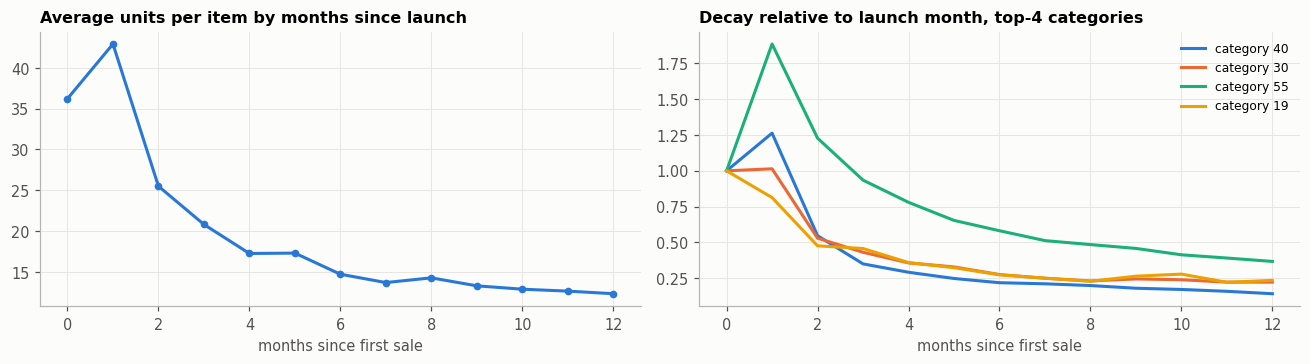

Launch month vs month 1: 0.8x | month 1 vs month 6: 2.9x


In [14]:
first_month = tr0.groupby('item_id').date_block_num.min()
lc = tr0[tr0.item_id.map(first_month) >= 1]  # exclude items already on sale in month 0 (left-censored)
lc = lc.assign(age=lc.date_block_num - lc.item_id.map(first_month))
# Average units per item at each age (months since its first sale)
curve = lc.groupby(['item_id', 'age']).item_cnt_day.sum().groupby('age').mean()
top_cats = cat_units.index[:4]
decay = {}
for cid in top_cats:
    cc = lc[lc.item_category_id == cid].groupby(['item_id', 'age']).item_cnt_day.sum().groupby('age').mean().reindex(range(13))
    decay[f'category {cid}'] = cc / cc.iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
line_chart(ax[0], range(13), {'all items': curve.reindex(range(13)).values}, 'Average units per item by months since launch',
           xlabel='months since first sale', marker='o')
line_chart(ax[1], range(13), decay, 'Decay relative to launch month, top-4 categories', xlabel='months since first sale')
plt.tight_layout(); plt.show()
print(f"Launch month vs month 1: {curve.iloc[0] / curve.iloc[1]:.1f}x | month 1 vs month 6: {curve.iloc[1] / curve.iloc[6]:.1f}x")

- Doanh số đạt đỉnh ở **tháng đầy đủ đầu tiên sau ra mắt**; tháng ra mắt chỉ bằng 0.8 lần tháng 1 (thường là tháng lẻ)
- Giảm nhanh: tháng 1 -> tháng 6 thấp hơn 2.9 lần
- Tốc độ giảm khác nhau theo category
- Build các features: item age, pair age, số tháng từ lần bán cuối, new-item flag, launch mean theo category

### 3.4 Sparsity & persistence on the monthly grid

- Lag: giá trị của cùng một biến ở các tháng trước - lag 1 = tháng trước, lag 12 = cùng tháng năm trước (vd dự báo tháng 11/2015: lag 1 = doanh số tháng 10/2015, lag 12 = doanh số tháng 11/2014)

In [15]:
def clean_transactions(df):
    """Cleaning rules derived in §2.1 and §3.2."""
    df = df.drop_duplicates().copy()
    df = df[(df.item_price < 100_000) & (df.item_cnt_day < 1000)]
    bad = df.item_price <= 0
    if bad.any():  # replace non-positive price by the median price of the same item-shop-month
        med = df[~bad].groupby(['date_block_num', 'shop_id', 'item_id']).item_price.median()
        key = pd.MultiIndex.from_frame(df.loc[bad, ['date_block_num', 'shop_id', 'item_id']])
        df.loc[bad, 'item_price'] = med.reindex(key).values
        df = df[df.item_price > 0]
    df['shop_id'] = df.shop_id.replace(SHOP_MAP)
    df['revenue'] = df.item_price * df.item_cnt_day
    return df

def build_grid(tr):
    """Monthly grid = shops active in month × items sold in month (mirrors the test construction), with target y."""
    parts = []
    # Cartesian product per month: every shop active that month × every item sold that month
    for m, g in tr.groupby('date_block_num'):
        parts.append(pd.MultiIndex.from_product([[m], g.shop_id.unique(), g.item_id.unique()],
                                                names=['date_block_num', 'shop_id', 'item_id']).to_frame(index=False))
    grid = pd.concat(parts, ignore_index=True)
    agg = tr.groupby(['date_block_num', 'shop_id', 'item_id']).item_cnt_day.sum().rename('y').reset_index()
    agg['has_txn'] = 1
    # Cells without any transaction get y = 0 (this is what makes the grid look like the test set)
    grid = grid.merge(agg, how='left', on=['date_block_num', 'shop_id', 'item_id'])
    grid['y'] = grid.y.fillna(0).clip(lower=0).astype('float32')
    grid['has_txn'] = grid.has_txn.fillna(0).astype('int8')
    return grid

tr = clean_transactions(train_raw)
test = test_raw.assign(shop_id=test_raw.shop_id.replace(SHOP_MAP))
grid_a = build_grid(tr)
print(f'Cleaned transactions: {len(tr):,} rows (removed {len(train_raw) - len(tr)}) | grid: {len(grid_a):,} rows')

g = grid_a.sort_values(['shop_id', 'item_id', 'date_block_num'])
# Shift the grid by one month to get last month's value (y_prev) of each pair
prev = grid_a.assign(date_block_num=grid_a.date_block_num + 1)[['date_block_num', 'shop_id', 'item_id', 'y']].rename(columns={'y': 'y_prev'})
gp = grid_a[grid_a.date_block_num >= 24].merge(prev, how='left', on=['date_block_num', 'shop_id', 'item_id']).fillna({'y_prev': 0})
# Transition table: P(sells this month | sold / did not sell last month)
trans = pd.crosstab(gp.y_prev > 0, gp.y > 0, normalize='index').rename(index={False: 'last month = 0', True: 'last month > 0'},
                                                                          columns={False: 'P(this month = 0)', True: 'P(this month > 0)'})
print(f"Share of zeros on the grid (2015): {(gp.y == 0).mean():.1%} | mean y: {gp.y.mean():.3f}")
trans

Cleaned transactions: 2,935,840 rows (removed 9) | grid: 10,913,804 rows


Share of zeros on the grid (2015): 85.8% | mean y: 0.306


y,P(this month = 0),P(this month > 0)
y_prev,,
last month = 0,0.9093,0.0907
last month > 0,0.5523,0.4477


- 85.8% ô của grid (name 2015) bằng 0 , tương tự  khớp mức 86.6% trên tập test
- shop-item có bán tháng trước: thì 45% bán tiếp; cặp đang bằng 0: thì chỉ 9%
- -> Lag tháng trước là baseline mạnh; cần thử loss cho dữ liệu zero-inflated (Tweedie)

### 3.5 Autocorrelation - which lags matter?

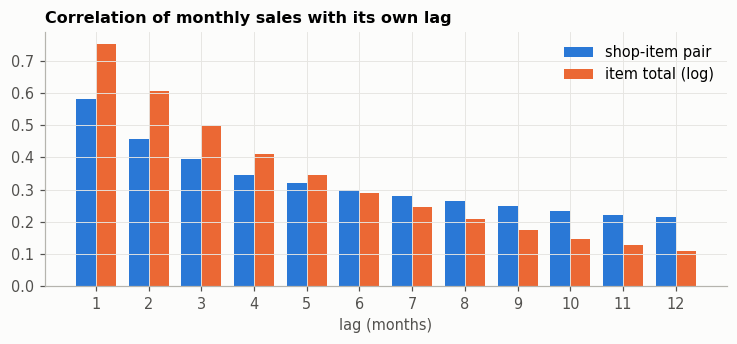

In [16]:
recent = grid_a[grid_a.date_block_num >= 12][['date_block_num', 'shop_id', 'item_id', 'y']]
ac_pair, ac_item = {}, {}
item_tot = grid_a.groupby(['date_block_num', 'item_id']).y.sum().reset_index()
# For each lag l, correlate y(t) with y(t-l): pair level (clipped at 20 against outliers) and item level (log of totals)
for l in range(1, 13):
    lagged = grid_a[['date_block_num', 'shop_id', 'item_id', 'y']].assign(date_block_num=lambda d: d.date_block_num + l).rename(columns={'y': 'yl'})
    m = recent.merge(lagged, how='left', on=['date_block_num', 'shop_id', 'item_id']).fillna({'yl': 0})
    ac_pair[l] = np.corrcoef(m.y.clip(0, 20), m.yl.clip(0, 20))[0, 1]
    li = item_tot.assign(date_block_num=item_tot.date_block_num + l).rename(columns={'y': 'yl'})
    mi = item_tot[item_tot.date_block_num >= 12].merge(li, how='left', on=['date_block_num', 'item_id']).fillna({'yl': 0})
    ac_item[l] = np.corrcoef(np.log1p(mi.y), np.log1p(mi.yl.clip(lower=0)))[0, 1]
fig, ax = plt.subplots(figsize=(8, 3))
w = 0.38
bar_chart(ax, np.arange(1, 13) - w / 2, list(ac_pair.values()), 'Correlation of monthly sales with its own lag', width=w, label='shop-item pair')
bar_chart(ax, np.arange(1, 13) + w / 2, list(ac_item.values()), 'Correlation of monthly sales with its own lag', width=w,
          colors=PALETTE[1], label='item total (log)', xlabel='lag (months)')
ax.set_xticks(range(1, 13)); ax.legend()
plt.show()

- Correlation cao nhất ở lag 1, giảm nhanh đến lag 3
- Lag 12 chỉ có bump nhỏ -> seasonality theo năm yếu
- Tổng theo item tự tương quan mạnh hơn từng cặp (ít nhiễu hơn)
- -> Pair lags 1, 2, 3, 6, 12 + rolling mean 3 tháng + trend; item-level lags 1-3

### 3.6 Price analysis

Pairs with a >5% month-on-month price change: 112,507 | log-log elasticity slope: -0.52
Median coefficient of variation of an item's price across shops in a month: 0.023


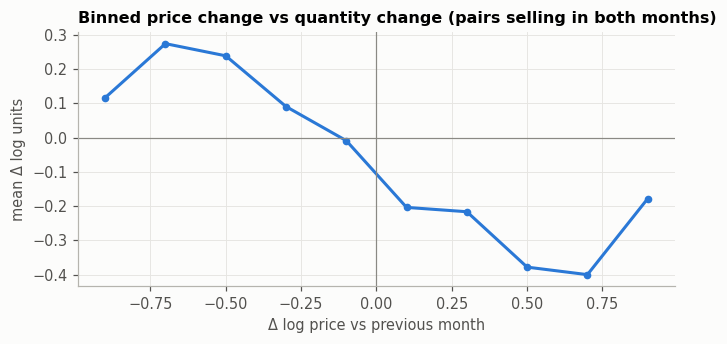

In [17]:
pm = tr.groupby(['date_block_num', 'shop_id', 'item_id']).agg(q=('item_cnt_day', 'sum'), rev=('revenue', 'sum')).reset_index()
pm = pm[pm.q > 0].assign(price=lambda d: d.rev / d.q)
# Pair each shop-item-month with the same pair one month earlier to measure price and quantity changes
pp = pm.merge(pm.assign(date_block_num=pm.date_block_num + 1), on=['date_block_num', 'shop_id', 'item_id'], suffixes=('', '_prev'))
pp['dlogp'] = np.log(pp.price / pp.price_prev)
pp['dlogq'] = np.log(pp.q / pp.q_prev)
chg = pp[pp.dlogp.abs() > 0.05]
# Slope of Δlog(units) on Δlog(price) = price elasticity (only real price changes > 5%)
slope = np.polyfit(chg.dlogp.clip(-1, 1), chg.dlogq, 1)[0]
# Price dispersion across shops: coefficient of variation of an item's price within the same month
cv = pm.groupby(['date_block_num', 'item_id']).price.agg(['std', 'mean', 'count']).query('count >= 5')
print(f"Pairs with a >5% month-on-month price change: {len(chg):,} | log-log elasticity slope: {slope:.2f}")
print(f"Median coefficient of variation of an item's price across shops in a month: {(cv['std'] / cv['mean']).median():.3f}")
bins = pd.cut(chg.dlogp.clip(-1, 1), np.linspace(-1, 1, 11))
b = chg.groupby(bins, observed=True).dlogq.agg(['mean', 'count'])
fig, ax = plt.subplots(figsize=(7, 3))
line_chart(ax, [i.mid for i in b.index], {'mean Δ log units': b['mean']}, 'Binned price change vs quantity change (pairs selling in both months)',
           xlabel='Δ log price vs previous month', ylabel='mean Δ log units', marker='o')
ax.axhline(0, color=GRAY, lw=0.8); ax.axvline(0, color=GRAY, lw=0.8)
plt.show()

- 112,507 lần đổi giá > 5%; elasticity log-log ≈ **-0.52** -> giảm giá 10% ~ tăng ~5% số lượng
- Chỉ đo trên cặp có bán ở cả 2 tháng -> cần aware là: có selection bias
- Giá gần như đồng nhất giữa các shop (CV ~2%)
- -> Price features ở level item: giá tháng trước, thay đổi so với lịch sử, giá tương đối trong category

### 3.7 Cold start - brand-new items

In [18]:
launch = grid_a.merge(items, on='item_id').merge(first_month.rename('first').reset_index(), on='item_id')
# Keep only each item's launch month (items already on sale in month 0 are excluded)
launch = launch[(launch.date_block_num == launch['first']) & (launch['first'] >= 1)]
lm = launch.groupby('item_category_id').y.agg(['mean', 'count'])
print(f"Average units per shop in an item's launch month: {launch.y.mean():.2f} (vs {grid_a[grid_a.date_block_num >= 1].y.mean():.2f} overall); "
      f"range across categories (≥500 rows): {lm[lm['count'] >= 500]['mean'].min():.2f} – {lm[lm['count'] >= 500]['mean'].max():.2f}")

# Hypothesis: without names, item_id order still encodes product similarity (IDs appear to be assigned alphabetically).
its = items.sort_values('item_id')
same_cat_adj = (its.item_category_id.values[1:] == its.item_category_id.values[:-1]).mean()
same_cat_rand = ((items.item_category_id.value_counts(normalize=True)) ** 2).sum()
lt = launch.groupby('item_id').agg(first=('first', 'first'), y=('y', 'mean'))
# Compare each launched item with the next item_id (its ID neighbour)
nb = lt.reindex(lt.index + 1).set_axis(lt.index)
both = lt.join(nb, rsuffix='_next').dropna()
same_launch = both[both['first'] == both['first_next']]
print(f"Adjacent item_ids share a category: {same_cat_adj:.0%} (random pairs: {same_cat_rand:.0%})")
print(f"Adjacent items launched in the same month: {len(same_launch) / len(both):.0%}; "
      f"correlation of their launch-month sales (log): {np.corrcoef(np.log1p(same_launch.y), np.log1p(same_launch.y_next))[0, 1]:.2f}")

Average units per shop in an item's launch month: 0.78 (vs 0.33 overall); range across categories (≥500 rows): 0.02 – 9.19
Adjacent item_ids share a category: 54% (random pairs: 8%)
Adjacent items launched in the same month: 29%; correlation of their launch-month sales (log): 0.69


- Tháng ra mắt: trung bình 0.78 units/shop so với 0.33 chung; dao động 0.02-9.19 theo category
- Item ID liền kề cùng category 54% (cặp ngẫu nhiên: 8%)
- 29% item liền kề ra mắt cùng tháng; doanh số tháng ra mắt tương quan 0.69
- -> ID có vẻ được gán theo thứ tự tên -> item lân cận là cùng một họ sản phẩm
- -> Nếu đúng giả định đó thì thử các feature dạng: category launch mean, sales của item ID ±1/±2, `item_id`

### 3.8 Spikes and high-volume items

In [19]:
# Squared error of the naive forecast (last month) per pair; then the share caused by the top-5 pairs
yv = grid_a[grid_a.date_block_num.isin([31, 32, 33])].merge(prev, how='left', on=['date_block_num', 'shop_id', 'item_id']).fillna({'y_prev': 0})
yv['se'] = (yv.y - yv.y_prev) ** 2
rows = []
for m, d in yv.groupby('date_block_num'):
    top = d.nlargest(5, 'se')
    rows.append({'month': m, 'pairs': len(d), 'share of squared error from top-5 pairs': top.se.sum() / d.se.sum(),
                 'share of units from pairs > 20': d.y[d.y > 20].sum() / d.y.sum(),
                 'top pairs (shop, item, cat, units)': [(int(r.shop_id), int(r.item_id), int(items.item_category_id[r.item_id]), int(r.y)) for r in top.head(3).itertuples()]})
pd.set_option('display.max_colwidth', 120)
pd.DataFrame(rows)

,month,pairs,share of squared error from top-5 pairs,share of units from pairs > 20,"top pairs (shop, item, cat, units)"
0,31,214536,0.1914,0.1006,"[(38, 20949, 71, 168), (12, 11373, 9, 75), (55, 9251, 8, 193)]"
1,32,218655,0.7958,0.2761,"[(55, 9249, 8, 1644), (12, 9248, 80, 1644), (55, 9251, 8, 1117)]"
2,33,238172,0.3412,0.1755,"[(12, 20949, 71, 500), (9, 4201, 75, 194), (25, 10201, 28, 166)]"


- Tháng 32: **5 cặp / khoảng 219k** gây ra khoảng 80% squared error của dự báo naive
- Đó là item 9244-9251 (category 8/80) bán cùng số lượng lớn (1,644) ở shop 55 và 12 trong một tháng -> sản phẩm sự kiện, không dự báo được
- 10-28% units mỗi tháng đến từ các cặp bán > 20/tháng -> item high-volume là thật
- -> Dẫn nếu nếu dùng Pair RMSE thô là metric nhiễu; clip target ở 20 sẽ dự báo thiếu item bán chạy -> cần metric khác và so sánh loss

### 3.9 Analysis summary

- Test là full grid, ~87% bằng 0 -> cần train trên monthly grid giống test
- Shop trùng (0/57, 1/58, 11/10) -> gộp ID; grid chỉ gồm shop active
- Trend giảm, tháng 11 gần trung tính -> chú ý các feature:  month-of-year, lagged means, seasonal baseline
- Persistence mạnh, autocorrelation giảm nhanh -> pair lags 1/2/3/6/12, rolling mean, trend, recency
- Đỉnh sau ra mắt, decay theo category -> lifecycle features
- 7% item mới, ID liền kề tương tự nhau -> cold-start features
- Elasticity âm, giá ở level item -> item-level price features
- Vài event chi phối squared error -> metric robust, so sánh các loss

## 4. Data Processing & Feature Engineering

### 4.1 Feature construction

In [20]:
K = ['date_block_num', 'shop_id', 'item_id']

def add_lags(df, src, keys, lags, name):
    """Join `src[name]` from month t-l onto month t for each lag l."""
    for l in lags:
        # Shift the source forward by l months so that month t receives the value of month t-l
        s = src.assign(date_block_num=src.date_block_num + l).rename(columns={name: f'{name}_lag{l}'})
        df = df.merge(s, on=['date_block_num'] + keys, how='left')
    return df

def last_event(df, events, keys, col):
    """Months since the last event (strictly before t) for the given keys, via an as-of join."""
    ev = events[['date_block_num'] + keys].drop_duplicates().rename(columns={'date_block_num': '_m'}).sort_values('_m')
    # As-of join: for each row, the latest event month strictly before t with the same keys
    out = pd.merge_asof(df[['date_block_num'] + keys].reset_index().sort_values('date_block_num'), ev,
                        left_on='date_block_num', right_on='_m', by=keys, allow_exact_matches=False)
    return (out.set_index('index').sort_index().eval('date_block_num - _m')).rename(col)

def build_features(tr, target_pairs, T):
    """tr: cleaned transactions with months < T. target_pairs: (shop_id, item_id) to forecast for month T."""
    hist = build_grid(tr[tr.date_block_num < T])
    df = pd.concat([hist, target_pairs[['shop_id', 'item_id']].assign(date_block_num=T, y=np.nan, has_txn=0)], ignore_index=True)
    df = df.merge(items, on='item_id', how='left')
    # `past` = rows with a known target; every statistic below is computed from it only (no leakage)
    past = df[df.date_block_num < T]

    # Pair lags, rolling stats and trend
    df = add_lags(df, past[K + ['y']].rename(columns={'y': 'pair'}), ['shop_id', 'item_id'], [1, 2, 3, 6, 12], 'pair')
    lag_cols = [c for c in df.columns if c.startswith('pair_lag')]
    df[lag_cols] = df[lag_cols].fillna(0)
    df['pair_roll3'] = df[['pair_lag1', 'pair_lag2', 'pair_lag3']].mean(axis=1)
    df['pair_trend'] = df.pair_lag1 - df.pair_lag2

    # Lagged target encodings (means over the grid at month t-l)
    for keys, name, lags in [(['item_id'], 'item_mean', [1, 2, 3]), (['shop_id'], 'shop_mean', [1]),
                             (['item_category_id'], 'cat_mean', [1, 12]), (['shop_id', 'item_category_id'], 'shopcat_mean', [1]),
                             ([], 'all_mean', [1])]:
        s = past.groupby(['date_block_num'] + keys).y.mean().rename(name).reset_index()
        df = add_lags(df, s, keys, lags, name)
    s = past.groupby(['date_block_num', 'item_id']).y.sum().rename('item_sum').reset_index()
    df = add_lags(df, s, ['item_id'], [1], 'item_sum')
    df['item_sum_lag1'] = df.item_sum_lag1.fillna(0)

    # Lifecycle / recency
    t = df.date_block_num
    item_first = df.item_id.map(tr.groupby('item_id').date_block_num.min())
    shop_first = df.shop_id.map(tr.groupby('shop_id').date_block_num.min())
    df['is_new_item'] = (item_first.isna() | (item_first >= t)).astype('int8')
    df['item_age'] = (t - item_first).where(item_first < t, 0)
    df['shop_age'] = (t - shop_first).where(shop_first < t, 0)
    df['m_since_pair_sale'] = last_event(df, past[past.y > 0], ['shop_id', 'item_id'], 'm')
    df['m_since_item_sale'] = last_event(df, past[past.y > 0], ['item_id'], 'm')
    pair_first = tr.groupby(['shop_id', 'item_id']).date_block_num.min().rename('pf').reset_index()
    pf = df[['shop_id', 'item_id']].merge(pair_first, how='left', on=['shop_id', 'item_id']).pf.values
    df['pair_age'] = np.where(pf < t, t - pf, -1)

    # Cold start: category launch-month mean (expanding, past only) and ID-neighbour sales
    first = past.item_id.map(tr.groupby('item_id').date_block_num.min())
    lr = past[past.date_block_num == first].groupby(['date_block_num', 'item_category_id']).y.agg(['sum', 'count']).reset_index()
    rows = []
    # For month m: average launch-month sales per category, using launches strictly before m
    for m in range(1, T + 1):
        h = lr[lr.date_block_num < m].groupby('item_category_id')[['sum', 'count']].sum()
        rows.append(pd.DataFrame({'item_category_id': h.index, 'cat_launch_mean': (h['sum'] / h['count']).values, 'date_block_num': m}))
    df = df.merge(pd.concat(rows), on=['date_block_num', 'item_category_id'], how='left')
    # Neighbour signal: mean last-month sales of the items with ID ±1 and ±2
    nb = df[['date_block_num', 'item_id', 'item_sum_lag1']].drop_duplicates(['date_block_num', 'item_id'])
    nbm = pd.concat([nb.assign(item_id=nb.item_id - d) for d in (-2, -1, 1, 2)])
    nbm = nbm.groupby(['date_block_num', 'item_id']).item_sum_lag1.mean().rename('nb_item_sum_lag1').reset_index()
    df = df.merge(nbm, on=['date_block_num', 'item_id'], how='left')

    # Price (item level)
    p = tr.groupby(['date_block_num', 'item_id']).agg(rev=('revenue', 'sum'), q=('item_cnt_day', 'sum')).reset_index()
    p = p[p.q > 0].assign(price=lambda d: d.rev / d.q).sort_values('date_block_num')
    # Expanding mean of the item's monthly price up to each month (lagged by 1 below)
    p['price_hist'] = p.groupby('item_id').price.cumsum() / (p.groupby('item_id').cumcount() + 1)
    df = add_lags(df, p[['date_block_num', 'item_id', 'price']], ['item_id'], [1], 'price')
    df = add_lags(df, p[['date_block_num', 'item_id', 'price_hist']], ['item_id'], [1], 'price_hist')
    df['price_delta'] = df.price_lag1 / df.price_hist_lag1 - 1
    df['price_rel_cat'] = df.price_lag1 / df.groupby(['date_block_num', 'item_category_id']).price_lag1.transform('median')

    # Calendar
    df['month'] = (t % 12).astype('int8')
    df['days_in_month'] = pd.PeriodIndex.from_fields(year=2013 + t // 12, month=t % 12 + 1, freq='M').days_in_month.astype('int8')

    for c in df.columns:
        if df[c].dtype == 'float64':
            df[c] = df[c].astype('float32')
    return df

t0 = time.time()
df = build_features(tr, test, 34)
FEATURE_GROUPS = {
    'pair history': ['pair_lag1', 'pair_lag2', 'pair_lag3', 'pair_lag6', 'pair_lag12', 'pair_roll3', 'pair_trend', 'm_since_pair_sale', 'pair_age'],
    'target encodings': ['item_mean_lag1', 'item_mean_lag2', 'item_mean_lag3', 'shop_mean_lag1', 'cat_mean_lag1', 'cat_mean_lag12',
                         'shopcat_mean_lag1', 'all_mean_lag1', 'item_sum_lag1'],
    'lifecycle': ['item_age', 'is_new_item', 'shop_age', 'm_since_item_sale'],
    'cold start': ['cat_launch_mean', 'nb_item_sum_lag1', 'item_id'],
    'price': ['price_lag1', 'price_hist_lag1', 'price_delta', 'price_rel_cat'],
    'calendar & ids': ['month', 'days_in_month', 'shop_id', 'item_category_id'],
}
FEATS = [f for g in FEATURE_GROUPS.values() for f in g]
assert set(FEATS) <= set(df.columns), set(FEATS) - set(df.columns)
print(f'Feature matrix: {df.shape[0]:,} rows × {len(FEATS)} features | {df.memory_usage().sum() / 1e9:.2f} GB | {time.time() - t0:.0f}s')
df[df.date_block_num == 34][FEATS].describe().T[['count', 'mean', 'min', 'max']]

Feature matrix: 11,128,004 rows × 33 features | 1.77 GB | 44s


,count,mean,min,max
pair_lag1,"214,200.0000",0.2833,0.0000,500.0000
pair_lag2,"214,200.0000",0.2747,0.0000,473.0000
pair_lag3,"214,200.0000",0.2782,0.0000,436.0000
pair_lag6,"214,200.0000",0.2632,0.0000,742.0000
pair_lag12,"214,200.0000",0.3238,0.0000,772.0000
pair_roll3,"214,200.0000",0.2787,0.0000,446.6667
pair_trend,"214,200.0000",0.0086,-162.0000,500.0000
m_since_pair_sale,"111,429.0000",6.3689,1.0000,34.0000
pair_age,"214,200.0000",7.9330,-1.0000,34.0000
item_mean_lag1,"167,622.0000",0.3737,0.0227,92.6818


- Feature matrix: 11.1M dòng × 33 features
- 6 nhóm: pair history, target encodings, lifecycle, cold start, price, calendar & ids
- Tháng 34: item mới thiếu giá/lịch sử -> NaN, để LightGBM tự xử lý missing

## 5. Modeling

### 5.1 Metric strategy

- Primary - **item-level WAPE**: cộng dự báo của mọi shop thành tổng theo item rồi so với thực tế, ra % sai số trên tổng lượng bán
  - đúng con số người dùng xem trên web
  - không bị vài sự kiện bất thường chi phối
  - vẫn tính được khi có rất nhiều số 0
- Secondary - RMSE theo từng cặp shop-item: phạt nặng các sai số lớn; thêm bản clip 0-20 để so với benchmark Kaggle
- Guardrail - bias: tổng dự báo cao hay thấp hơn tổng thực tế bao nhiêu %; dự báo thiếu/thừa có hệ thống ảnh hưởng trực tiếp đến tồn kho
- Không dùng MAPE: phải chia cho giá trị thực tế, mà 86% là 0 nên không tính được
- Không dùng MAE theo cặp làm metric chính: model sẽ học cách dự báo gần 0 cho hầu hết các cặp, cộng lại thì tổng theo item bị thiếu nhiều

### 5.2 Validation design

In [21]:
FOLDS = [31, 32, 33]
MIN_TRAIN_MONTH = 12
data = df[df.date_block_num >= MIN_TRAIN_MONTH].reset_index(drop=True)
del df

def evaluate(y, p, item_ids):
    y, p = np.asarray(y, float), np.asarray(p, float)
    # Item-level view: sum forecasts and actuals over shops, then compare the totals
    it = pd.DataFrame({'i': item_ids, 'y': y, 'p': p}).groupby('i').sum()
    return {'item_WAPE': (it.y - it.p).abs().sum() / it.y.sum(), 'RMSE': np.sqrt(np.mean((y - p) ** 2)),
            'RMSE_clip20': np.sqrt(np.mean((np.clip(y, 0, 20) - np.clip(p, 0, 20)) ** 2)), 'bias': p.sum() / y.sum() - 1}

def summarize(rows):
    r = pd.DataFrame(rows)
    out = r.groupby('model', sort=False)[['item_WAPE', 'RMSE', 'RMSE_clip20', 'bias']].agg(['mean', 'std'])
    out.columns = [f'{a} {b}' for a, b in out.columns]
    return out

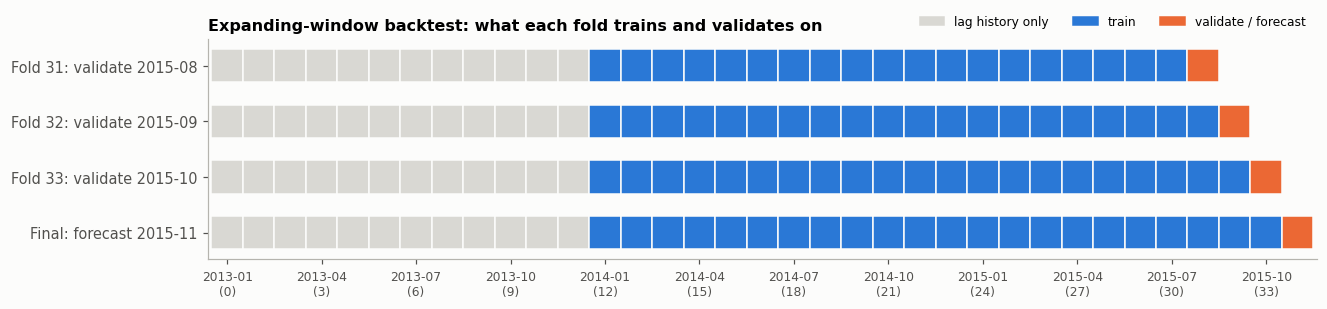

In [22]:
fig, ax = plt.subplots(figsize=(13, 2.6))
fold_timeline(ax, FOLDS, MIN_TRAIN_MONTH)
ax.set_title('Expanding-window backtest: what each fold trains and validates on')
plt.show()

- Mục đích: kiểm tra model đúng như cách nó sẽ được dùng - chỉ dùng dữ liệu đến tháng t-1 để dự báo tháng t (giống dùng dữ liệu đến 2015-10 để dự báo 2015-11)
- 3 fold, mỗi fold là một lần "giả vờ dự báo" (số trong ngoặc là `date_block_num`):
  - Fold 31: train 2014-01 -> 2015-07 (12-30), validate 2015-08 (31)
  - Fold 32: train 2014-01 -> 2015-08 (12-31), validate 2015-09 (32)
  - Fold 33: train 2014-01 -> 2015-09 (12-32), validate 2015-10 (33)
- Expanding window: mỗi fold train thêm 1 tháng, giống thực tế dữ liệu tích luỹ dần theo thời gian
- Dùng 3 fold thay vì 1 để xem kết quả có ổn định không - một tháng riêng lẻ có thể may/rủi (vd 2015-09 có sự kiện bất thường ở §3.8)
- Không random split: trộn ngẫu nhiên sẽ cho model "nhìn thấy tương lai" -> điểm validate đẹp giả
- 2013-01 -> 2013-12 (0-11) không đưa vào train vì chưa đủ 12 tháng lịch sử cho lag 12; chỉ dùng làm lịch sử để tính lag
- Không early stopping trên tháng validate: nếu dùng chính tháng validate để chọn số cây thì điểm validate có thể bị lạc quan

### 5.3 Baselines

In [23]:
tot = tr.groupby('date_block_num').item_cnt_day.sum()
baseline_rows = []
for v in FOLDS:
    val = data[data.date_block_num == v]
    # Seasonal ratio from last year: units(v-12) / units(v-13), e.g. Nov/Oct 2014 for Nov 2015
    season = tot[v - 12] / tot[v - 13]
    for name, pred in [('zero', np.zeros(len(val))), ('previous month', val.pair_lag1),
                       ('mean of last 3 months', val.pair_roll3), ('previous month × seasonal ratio', val.pair_lag1 * season)]:
        baseline_rows.append({'model': name, 'fold': v, **evaluate(val.y, pred, val.item_id)})
baselines = summarize(baseline_rows)
baselines

,item_WAPE mean,item_WAPE std,RMSE mean,RMSE std,RMSE_clip20 mean,RMSE_clip20 std,bias mean,bias std
model,,,,,,,,
zero,1.0000,0.0000,3.9414,2.5343,1.1500,0.0435,-1.0000,0.0000
previous month,0.5995,0.0785,3.2134,2.6565,1.0480,0.0968,-0.1188,0.0071
mean of last 3 months,0.6352,0.0623,3.3165,2.6479,0.9991,0.0754,-0.1326,0.0367
previous month × seasonal ratio,0.6136,0.0675,3.2685,2.6146,1.0692,0.0889,-0.0677,0.0748


- Previous month là baseline tốt nhất: cho item WAPE **0.600**
- Điều chỉnh thêm seasonal giúp giảm bias (khoảng -6778%) nhưng WAPE kém hơn (0.6136)
- Mọi baseline đều có bias âm vì item/cặp mới nhận giá trị 0
- -> Model phải thắng 0.600 ở mọi fold

### 5.4 Loss function / target treatment

In [24]:
BASE_PARAMS = dict(learning_rate=0.1, num_leaves=127, min_data_in_leaf=200, feature_fraction=0.7, bagging_fraction=0.8,
                   bagging_freq=1, lambda_l2=1.0, seed=SEED, verbose=-1, num_threads=8)
EXP_ROUNDS = 5 if FAST else 150

def run_cv(params, feats=FEATS, rounds=EXP_ROUNDS, cap=None, train_filter=None, name='model', keep_preds=False):
    rows, preds, models = [], {}, {}
    # Expanding window: train on every month before fold v, evaluate on month v (fixed number of trees)
    for v in FOLDS:
        trn = data[data.date_block_num < v]
        if train_filter is not None:
            trn = trn[train_filter(trn)]
        val = data[data.date_block_num == v]
        y = trn.y.clip(upper=cap) if cap else trn.y
        m = lgb.train(params, lgb.Dataset(trn[feats], y), rounds)
        p = np.clip(m.predict(val[feats]), 0, None)
        rows.append({'model': name, 'fold': v, **evaluate(val.y, p, val.item_id)})
        if keep_preds:
            preds[v], models[v] = p, m
    return (rows, preds, models) if keep_preds else rows

t0 = time.time()
loss_rows = []
loss_rows += run_cv({**BASE_PARAMS, 'objective': 'regression'}, name='L2, raw target')
loss_rows += run_cv({**BASE_PARAMS, 'objective': 'regression'}, cap=20, name='L2, target clipped at 20')
loss_rows += run_cv({**BASE_PARAMS, 'objective': 'tweedie', 'tweedie_variance_power': 1.3}, name='Tweedie p=1.3, raw target')
loss_rows += run_cv({**BASE_PARAMS, 'objective': 'tweedie', 'tweedie_variance_power': 1.5}, name='Tweedie p=1.5, raw target')
print(f'{time.time() - t0:.0f}s')
pd.concat([baselines.loc[['previous month']], summarize(loss_rows)])

344s


,item_WAPE mean,item_WAPE std,RMSE mean,RMSE std,RMSE_clip20 mean,RMSE_clip20 std,bias mean,bias std
model,,,,,,,,
previous month,0.5995,0.0785,3.2134,2.6565,1.0480,0.0968,-0.1188,0.0071
"L2, raw target",0.6059,0.0961,3.2131,2.6903,0.9648,0.1385,0.0559,0.1304
"L2, target clipped at 20",0.5695,0.0636,3.6867,2.5946,0.8278,0.0748,-0.1000,0.0496
"Tweedie p=1.3, raw target",0.5138,0.0431,3.1073,2.7244,0.8435,0.0769,-0.0938,0.0605
"Tweedie p=1.5, raw target",0.5107,0.0477,3.1059,2.7991,0.8448,0.0747,-0.1103,0.0617


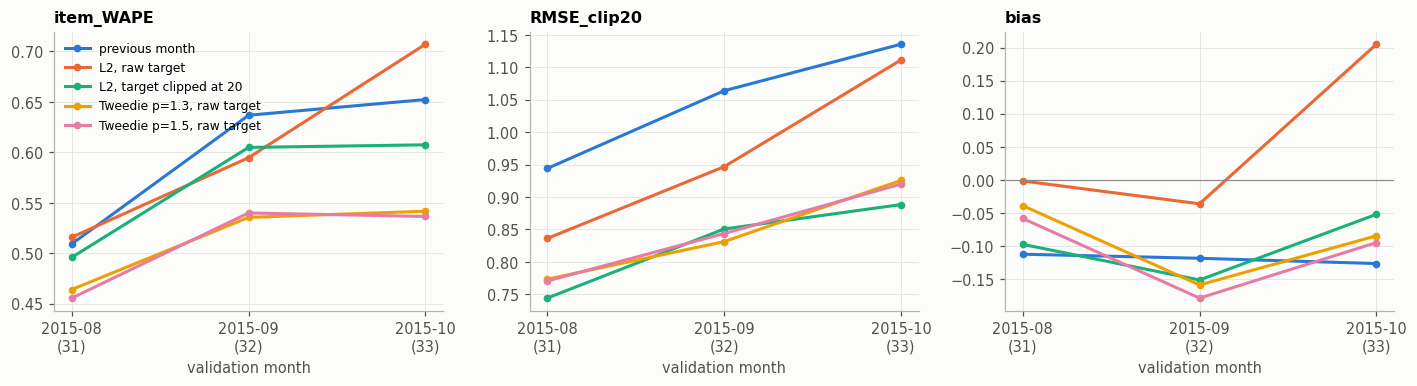

In [25]:
lr = pd.DataFrame(baseline_rows + loss_rows)
order = ['previous month', 'L2, raw target', 'L2, target clipped at 20', 'Tweedie p=1.3, raw target', 'Tweedie p=1.5, raw target']
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, metric in zip(ax, ['item_WAPE', 'RMSE_clip20', 'bias']):
    series = {name: lr[lr.model == name].sort_values('fold')[metric].values for name in order}
    line_chart(a, FOLDS, series, metric, xlabel='validation month', marker='o')
    a.set_xticks(FOLDS); a.set_xticklabels([f'{month_label(v)}\n({v})' for v in FOLDS])
    if a is not ax[0]:
        a.get_legend().remove()
ax[2].axhline(0, color=GRAY, lw=0.8)
plt.tight_layout(); plt.show()

- L2 raw: WAPE 0.606 - không thắng baseline; bias dao động -4% -> +20% giữa các fold
- L2 clip 20: clipped-RMSE tốt nhất (0.828) nhưng WAPE 0.570, dự báo thiếu item bán chạy
- Tweedie raw: WAPE tốt nhất (0.511-0.514), RMSE tốt nhất, bias -9%
- -> Chọn Tweedie trên raw target

### 5.5 Grid vs. transactions-only training

In [26]:
TWEEDIE = {**BASE_PARAMS, 'objective': 'tweedie', 'tweedie_variance_power': 1.3}
t0 = time.time()
grid_rows = run_cv(TWEEDIE, train_filter=lambda d: d.has_txn == 1, name='trained on transactions only')
print(f'{time.time() - t0:.0f}s')
summarize([r for r in loss_rows if r['model'].startswith('Tweedie p=1.3')] + grid_rows)

22s


,item_WAPE mean,item_WAPE std,RMSE mean,RMSE std,RMSE_clip20 mean,RMSE_clip20 std,bias mean,bias std
model,,,,,,,,
"Tweedie p=1.3, raw target",0.5138,0.0431,3.1073,2.7244,0.8435,0.0769,-0.0938,0.0605
trained on transactions only,3.7211,0.7385,3.4242,2.4989,1.5272,0.3730,3.4863,0.8318


- Chỉ train trên dòng có giao dịch: item WAPE **3.72**, bias **+349%**
- Train trên grid: WAPE 0.514, bias -9%
- -> Thiết kế training trên toàn bộ grid là quyết định quan trọng nhất

### 5.6 Feature-group ablation

In [27]:
t0 = time.time()
ref = summarize([r for r in loss_rows if r['model'].startswith('Tweedie p=1.3')]).iloc[0]
abl = []
for g, cols in FEATURE_GROUPS.items():
    feats = [f for f in FEATS if f not in cols]
    s = summarize(run_cv(TWEEDIE, feats=feats, name=f'without {g}')).iloc[0]
    abl.append({'dropped group': g, 'n features': len(cols), 'Δ item_WAPE': s['item_WAPE mean'] - ref['item_WAPE mean'],
                'Δ RMSE_clip20': s['RMSE_clip20 mean'] - ref['RMSE_clip20 mean'], 'Δ bias': s['bias mean'] - ref['bias mean']})
print(f'{time.time() - t0:.0f}s')
abl = pd.DataFrame(abl).sort_values('Δ item_WAPE', ascending=False)
abl

465s


,dropped group,n features,Δ item_WAPE,Δ RMSE_clip20,Δ bias
1,target encodings,9,0.0338,0.0098,0.0016
5,calendar & ids,4,0.0101,0.0150,-0.0059
3,cold start,3,0.0097,0.0029,0.0256
2,lifecycle,4,0.0091,0.0089,0.0089
4,price,4,0.0041,-0.0073,0.0131
0,pair history,9,0.0018,0.0139,0.0056


- Bỏ nhóm feature nào cũng làm item WAPE kém đi
- Target encodings quan trọng nhất (+0.034 WAPE khi bị bỏ)
- Pair history: WAPE chỉ +0.002 (trùng thông tin với encodings) nhưng clipped-RMSE +0.014
- Cold start và lifecycle giảm bias nhiều nhất
- Price: tốt cho WAPE/bias, hơi kém clipped-RMSE (-0.007)
- -> Quyết định giữ cả 6 nhóm features

### 5.7 Hyper-parameter selection

In [28]:
t0 = time.time()
cands = [dict(num_leaves=63, min_data_in_leaf=200, tweedie_variance_power=1.3),
         dict(num_leaves=255, min_data_in_leaf=500, tweedie_variance_power=1.3),
         dict(num_leaves=127, min_data_in_leaf=200, tweedie_variance_power=1.2),
         dict(num_leaves=127, min_data_in_leaf=200, tweedie_variance_power=1.4)]
hp_rows = [r for r in loss_rows if r['model'].startswith('Tweedie p=1.3')]
for c in cands:
    hp_rows += run_cv({**TWEEDIE, **c}, name=f"leaves={c['num_leaves']}, min_leaf={c['min_data_in_leaf']}, p={c['tweedie_variance_power']}")
hp = summarize(hp_rows).rename(index={'Tweedie p=1.3, raw target': 'leaves=127, min_leaf=200, p=1.3'}).sort_values('item_WAPE mean')
print(f'{time.time() - t0:.0f}s')
hp

311s


,item_WAPE mean,item_WAPE std,RMSE mean,RMSE std,RMSE_clip20 mean,RMSE_clip20 std,bias mean,bias std
model,,,,,,,,
"leaves=255, min_leaf=500, p=1.3",0.5056,0.0403,3.1149,2.6792,0.8356,0.0659,-0.1086,0.0428
"leaves=127, min_leaf=200, p=1.4",0.5077,0.0449,3.0727,2.8053,0.8363,0.0633,-0.1025,0.0657
"leaves=127, min_leaf=200, p=1.3",0.5138,0.0431,3.1073,2.7244,0.8435,0.0769,-0.0938,0.0605
"leaves=127, min_leaf=200, p=1.2",0.5189,0.0451,3.1088,2.6972,0.8518,0.0611,-0.0904,0.0695
"leaves=63, min_leaf=200, p=1.3",0.5247,0.0438,3.0480,2.6218,0.8534,0.0735,-0.0632,0.0632


In [29]:
best_name = hp.index[0]
best = dict(kv.split('=') for kv in best_name.replace(' ', '').split(','))
FINAL_PARAMS = {**TWEEDIE, 'num_leaves': int(best['leaves']), 'min_data_in_leaf': int(best['min_leaf']),
                'tweedie_variance_power': float(best['p']), 'learning_rate': 0.05}

# Number of trees at the lower learning rate: early stopping on fold 32 only (fold 33 stays untouched for reporting).
trn, val = data[data.date_block_num < 32], data[data.date_block_num == 32]
es = lgb.train({**FINAL_PARAMS, 'metric': 'tweedie'}, lgb.Dataset(trn[FEATS], trn.y), 20 if FAST else 2000,
               valid_sets=[lgb.Dataset(val[FEATS], val.y)], callbacks=[lgb.early_stopping(50, verbose=False)])
FINAL_ROUNDS = es.best_iteration
print('Final parameters:', {k: FINAL_PARAMS[k] for k in ['num_leaves', 'min_data_in_leaf', 'tweedie_variance_power', 'learning_rate']},
      '| trees:', FINAL_ROUNDS)
del trn, val, es

Final parameters: {'num_leaves': 255, 'min_data_in_leaf': 500, 'tweedie_variance_power': 1.3, 'learning_rate': 0.05} | trees: 225


- Các cấu hình chênh nhau ≤ 0.02 WAPE (< nửa std giữa các fold, 0.04) -> model không nhạy hyper-parameter
- Chọn 255 leaves, min 500 rows/leaf, Tweedie power 1.3; 225 cây ở learning rate 0.05 (early stopping trên fold 32)

## 6. Evaluation & Error Analysis

### 6.1 Backtest of the final model

In [30]:
t0 = time.time()
final_rows, fold_preds, fold_models = run_cv(FINAL_PARAMS, rounds=FINAL_ROUNDS, name='LightGBM Tweedie (final)', keep_preds=True)
print(f'{time.time() - t0:.0f}s')
results = pd.concat([baselines, summarize(final_rows)])
per_fold = pd.DataFrame(baseline_rows + final_rows).pivot_table(index='model', columns='fold', values='item_WAPE').loc[results.index]
display(results)
print('item_WAPE per fold:'); display(per_fold)
best_base = per_fold.drop(index='LightGBM Tweedie (final)').min()
improve = 1 - per_fold.loc['LightGBM Tweedie (final)'] / best_base
print('Relative item-WAPE improvement vs best baseline per fold:', improve.round(3).to_dict())

136s


,item_WAPE mean,item_WAPE std,RMSE mean,RMSE std,RMSE_clip20 mean,RMSE_clip20 std,bias mean,bias std
model,,,,,,,,
zero,1.0000,0.0000,3.9414,2.5343,1.1500,0.0435,-1.0000,0.0000
previous month,0.5995,0.0785,3.2134,2.6565,1.0480,0.0968,-0.1188,0.0071
mean of last 3 months,0.6352,0.0623,3.3165,2.6479,0.9991,0.0754,-0.1326,0.0367
previous month × seasonal ratio,0.6136,0.0675,3.2685,2.6146,1.0692,0.0889,-0.0677,0.0748
LightGBM Tweedie (final),0.5102,0.0411,3.1052,2.7168,0.8432,0.0620,-0.0957,0.0681


item_WAPE per fold:


fold,31,32,33
model,,,
zero,1.0000,1.0000,1.0000
previous month,0.5093,0.6368,0.6523
mean of last 3 months,0.5674,0.6898,0.6484
previous month × seasonal ratio,0.5428,0.6207,0.6773
LightGBM Tweedie (final),0.4631,0.5379,0.5297


Relative item-WAPE improvement vs best baseline per fold: {31: 0.091, 32: 0.133, 33: 0.183}


- Model cho item WAPE **0.510** vs 0.600 (previous month); RMSE 3.11; RMSE clip 0.84; bias giảm 9.6%
- Tốt hơn baseline tốt nhất ở cả 3 fold: tốt hơn lần lượt 9%, 13%, 18%

### 6.2 Performance by segment (fold 33)

In [31]:
V = 33
val = data[data.date_block_num == V].copy()
val['pred'] = fold_preds[V]
# Same A/B/C segmentation as §2.4, using the features available at month 33
val['segment'] = np.select([val.pair_age >= 0, val.is_new_item == 0], ['A: pair has history', 'B: known item, new pair'], 'C: brand-new item')
seg_rows = []
for s, d in val.groupby('segment'):
    for name, p in [('previous month', d.pair_lag1), ('LightGBM', d.pred)]:
        seg_rows.append({'segment': s, 'model': name, 'rows': len(d), 'share of units': d.y.sum() / val.y.sum(), **evaluate(d.y, p, d.item_id)})
pd.DataFrame(seg_rows).set_index(['segment', 'model'])

rows  share of units  item_WAPE  \
segment                 model                                               
A: pair has history     previous month  117122          0.7098     0.6070   
                        LightGBM        117122          0.7098     0.4084   
B: known item, new pair previous month  100150          0.1263     1.0000   
                        LightGBM        100150          0.1263     0.8824   
C: brand-new item       previous month   20900          0.1638     1.0000   
                        LightGBM         20900          0.1638     0.9895   

                                         RMSE  RMSE_clip20    bias  
segment                 model                                       
A: pair has history     previous month 2.3855       1.2238  0.2310  
                        LightGBM       2.0954       0.8548 -0.0071  
B: known item, new pair previous month 1.2762       0.6725 -1.0000  
                        LightGBM       1.2348       0.6263 -0.3681  
C: brand-new item       previous month 3.3810       2.0352 -1.0000  
                        LightGBM       3.0477       1.8217 -0.1298

- A - cặp có lịch sử (71% units): WAPE **0.41** vs 0.61 naive, bias ≈ 0
- B - item cũ, shop mới (13%): naive = 0; model lấy lại ~63% volume, WAPE 0.88
- C - item hoàn toàn mới (16%): bias -13% nhưng WAPE ≈ 0.99 -> đúng mức tổng, không biết item nào sẽ bán chạy
- -> Item mới nên được gắn nhãn *low confidence*

### 6.3 Error by category and largest misses

In [32]:
# Item-level absolute error aggregated by category
cat_err = val.groupby('item_category_id').apply(lambda d: pd.Series({'units': d.y.sum(), 'forecast': d.pred.sum(),
                                                                     'abs error (item level)': (d.groupby('item_id').y.sum() - d.groupby('item_id').pred.sum()).abs().sum()}))
cat_err['share of total abs error'] = cat_err['abs error (item level)'] / cat_err['abs error (item level)'].sum()
cat_err['bias'] = cat_err.forecast / cat_err.units - 1
display(cat_err.sort_values('share of total abs error', ascending=False).head(8))
it_err = val.groupby('item_id').agg(units=('y', 'sum'), forecast=('pred', 'sum'), category=('item_category_id', 'first'), last_month=('pair_lag1', 'sum'))
it_err['abs error'] = (it_err.units - it_err.forecast).abs()
it_err.sort_values('abs error', ascending=False).head(8)

,units,forecast,abs error (item level),share of total abs error,bias
item_category_id,,,,,
20,"6,596.0000","6,675.5929","5,637.4482",0.1545,0.0121
40,"7,680.0000","6,773.0953","3,680.1863",0.1008,-0.1181
55,"5,808.0000","5,381.5532","2,361.7597",0.0647,-0.0734
28,"2,857.0000","1,652.7676","2,338.2511",0.0641,-0.4215
47,"3,421.0000","1,476.6231","2,262.4423",0.0620,-0.5684
37,"4,061.0000","2,735.5474","2,240.4930",0.0614,-0.3264
30,"4,150.0000","4,280.2518","1,689.7638",0.0463,0.0314
61,"2,291.0000","1,227.0199","1,649.7509",0.0452,-0.4644


,units,forecast,category,last_month,abs error
item_id,,,,,
10201,"1,334.0000",176.3128,28,0.0000,"1,157.6872"
10202,899.0000,143.3182,20,0.0000,755.6818
7223,798.0000,122.5354,20,0.0000,675.4646
1583,660.0000,266.0751,20,0.0000,393.9249
7224,504.0000,122.5354,20,0.0000,381.4646
15069,458.0000,131.1332,28,301.0000,326.8668
17755,37.0000,324.5345,20,0.0000,287.5345
6505,34.0000,313.1348,28,0.0000,279.1348


- 4 category (20, 40, 55, 28) chiếm ~37% error ở level item
- Sai số lớn nhất: sản phẩm mới phát hành trong tháng (10201/10202, 7223/7224 - ID liền kề) bán 500-1,300 units dù không có lịch sử
- Category 28, 47, 37, 61 bị dự báo thiếu 30-60%
- -> Phần error còn lại chủ yếu là exogenous (lịch phát hành, khuyến mãi)

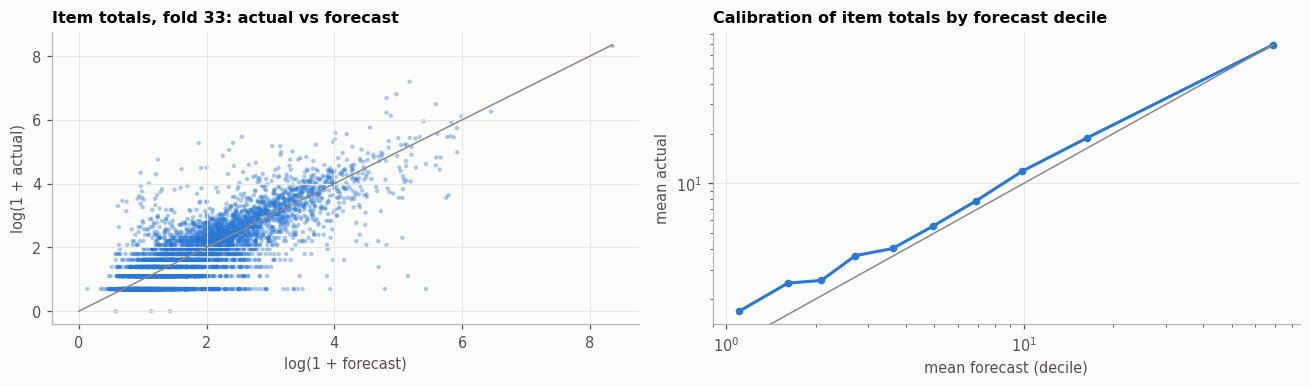

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
itp = val.groupby('item_id')[['y', 'pred']].sum()
lim = max(itp.y.max(), itp.pred.max())
ax[0].scatter(np.log1p(itp.pred), np.log1p(itp.y), s=8, alpha=0.4, color=PALETTE[0], edgecolor='none')
ax[0].plot([0, np.log1p(lim)], [0, np.log1p(lim)], color=GRAY, lw=1)
ax[0].set_xlabel('log(1 + forecast)'); ax[0].set_ylabel('log(1 + actual)'); ax[0].set_title('Item totals, fold 33: actual vs forecast')
# Calibration: mean actual vs mean forecast inside each forecast decile (on the diagonal = well calibrated)
bins = pd.qcut(itp.pred, 10, duplicates='drop')
cal = itp.groupby(bins, observed=True).agg(pred=('pred', 'mean'), y=('y', 'mean'))
line_chart(ax[1], cal.pred, {'mean actual': cal.y}, 'Calibration of item totals by forecast decile',
           xlabel='mean forecast (decile)', ylabel='mean actual', marker='o')
ax[1].plot([0, cal.pred.max()], [0, cal.pred.max()], color=GRAY, lw=1)
ax[1].set_xscale('log'); ax[1].set_yscale('log')
plt.tight_layout(); plt.show()

- Item có dự báo lớn: calibrate tốt (nằm trên đường chéo)
- Item có dự báo nhỏ: thực tế ≈ 1.5-2× dự báo -> cùng với segment B/C là nguồn chính của bias -10%
- -> Không nhân hệ số toàn cục (sẽ thổi phồng 87% ô bằng 0); cần calibration theo segment là next step

### 6.4 Interpretability - feature importance and SHAP

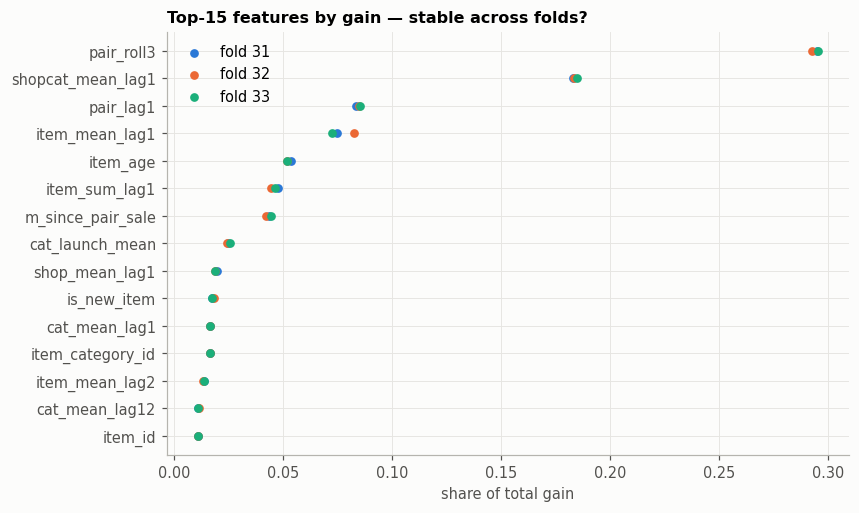

In [34]:
imp = pd.DataFrame({v: pd.Series(m.feature_importance('gain'), index=FEATS) for v, m in fold_models.items()})
imp = imp / imp.sum()
imp['mean'] = imp.mean(axis=1)
imp = imp.sort_values('mean', ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
top = imp.head(15)[::-1]
for i, v in enumerate(FOLDS):
    ax.scatter(top[v], range(len(top)), color=PALETTE[i], s=22, label=f'fold {v}', zorder=3)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index); ax.set_xlabel('share of total gain'); ax.set_title('Top-15 features by gain — stable across folds?'); ax.legend()
plt.show()

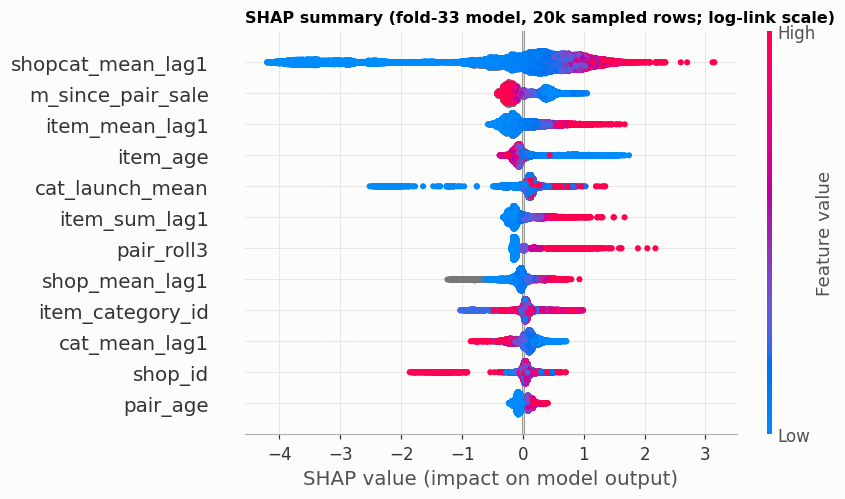

In [35]:
import shap
sample = val.sample(20000, random_state=SEED)
sv = shap.TreeExplainer(fold_models[V]).shap_values(sample[FEATS])
shap.summary_plot(sv, sample[FEATS], max_display=12, show=False, plot_size=(8, 4.5))
plt.title('SHAP summary (fold-33 model, 20k sampled rows; log-link scale)'); plt.show()

- Thứ hạng gain gần như giống hệt nhau ở cả 3 fold -> model ổn định
- Top features: `pair_roll3`, `shopcat_mean_lag1`, `pair_lag1`, `item_mean_lag1`, `item_age`
- SHAP: sales gần đây cao -> dự báo cao; lâu không bán -> thấp; item cũ -> thấp; category launch mean cao -> item mới cao

### 6.5 Uncertainty - prediction intervals for item totals

In [36]:
def item_totals(v):
    d = data.loc[data.date_block_num == v, ['item_id', 'y']].assign(pred=fold_preds[v])
    return d.groupby('item_id')[['y', 'pred']].sum()

# Split-conformal: quantile of item-total residuals per forecast-size bin
EDGES = [0, 1, 3, 10, 30, 100, np.inf]
def fit_conformal(t, level=0.8):
    b = pd.cut(t.pred, EDGES, right=False)
    return (t.y - t.pred).abs().groupby(b, observed=False).quantile(level).ffill().bfill().values

def apply_conformal(pred, q):
    w = q[pd.cut(pred, EDGES, right=False).codes]
    return np.clip(pred - w, 0, None), pred + w

q32 = fit_conformal(item_totals(32))
t33 = item_totals(33)
lo, hi = apply_conformal(t33.pred.values, q32)
print(f'Empirical coverage of 80% intervals on fold 33: {((t33.y >= lo) & (t33.y <= hi)).mean():.1%}')
Q_FINAL = fit_conformal(pd.concat([item_totals(32), t33]))
pd.DataFrame({'forecast bin': [f'[{a}, {b})' for a, b in zip(EDGES[:-1], EDGES[1:])], '80% half-width (units)': Q_FINAL})

Empirical coverage of 80% intervals on fold 33: 76.1%


,forecast bin,80% half-width (units)
0,"[0, 1)",1.0163
1,"[1, 3)",1.4768
2,"[3, 10)",4.0824
3,"[10, 30)",11.1229
4,"[30, 100)",32.1559
5,"[100, inf)",178.3395


- 80% interval đạt coverage 76% trên fold 33 -> thấp hơn danh nghĩa một chút
- Độ rộng: ~±1 unit (dự báo < 1) đến ~±178 units (dự báo ≥ 100)

## 7. Final Forecast & Artifacts

In [37]:
t0 = time.time()
trn = data[data.date_block_num < 34]
final_model = lgb.train(FINAL_PARAMS, lgb.Dataset(trn[FEATS], trn.y), int(FINAL_ROUNDS * 1.05))  # slightly more trees for one more month of data
del trn
te = data[data.date_block_num == 34].copy()
te['forecast'] = np.clip(final_model.predict(te[FEATS]), 0, None)
print(f'trained in {time.time() - t0:.0f}s')

# Map predictions back to the original test IDs (test shop ids go through the same duplicate-shop mapping)
out = test_raw.assign(shop_id_mapped=test_raw.shop_id.replace(SHOP_MAP)).merge(
    te[['shop_id', 'item_id', 'forecast', 'is_new_item', 'item_category_id']].rename(columns={'shop_id': 'shop_id_mapped'}),
    on=['shop_id_mapped', 'item_id'], how='left')
out = out[['ID', 'shop_id', 'item_id', 'item_category_id', 'forecast', 'is_new_item']]
assert len(out) == len(test_raw) == 214_200 and out.forecast.notna().all() and (out.forecast >= 0).all()

# Sanity check at aggregate level: bottom-up total vs October actuals on the same grid × historical Nov/Oct ratio
oct_on_grid = proj.oct_units.clip(lower=0).sum()
expected = oct_on_grid * np.mean(list(nov_oct.values()))
print(f"Forecast total Nov-2015 on test grid: {out.forecast.sum():,.0f} units | Oct-2015 actual on grid: {oct_on_grid:,.0f} | "
      f"Oct × avg Nov/Oct ratio: {expected:,.0f} -> ratio forecast/expected = {out.forecast.sum() / expected:.2f}")
out.describe().T

trained in 49s
Forecast total Nov-2015 on test grid: 67,042 units | Oct-2015 actual on grid: 62,857 | Oct × avg Nov/Oct ratio: 66,515 -> ratio forecast/expected = 1.01


,count,mean,std,min,25%,50%,75%,max
ID,"214,200.0000","107,099.5000","61,834.3582",0.0000,"53,549.7500","107,099.5000","160,649.2500","214,199.0000"
shop_id,"214,200.0000",31.6429,17.5619,2.0000,16.0000,34.5000,47.0000,59.0000
item_id,"214,200.0000","11,019.3986","6,252.6446",30.0000,"5,381.5000","11,203.0000","16,071.5000","22,167.0000"
item_category_id,"214,200.0000",46.3096,16.7166,0.0000,37.0000,43.0000,58.0000,83.0000
forecast,"214,200.0000",0.3130,3.0168,0.0000,0.0134,0.0706,0.2321,645.6633
is_new_item,"214,200.0000",0.0712,0.2571,0.0000,0.0000,0.0000,0.0000,1.0000


In [38]:
item_fc = out.groupby('item_id').agg(item_category_id=('item_category_id', 'first'), total_forecast=('forecast', 'sum'),
                                     is_new_item=('is_new_item', 'max'), n_shops=('shop_id', 'nunique')).reset_index()
item_fc['lower_80'], item_fc['upper_80'] = apply_conformal(item_fc.total_forecast.values, Q_FINAL)

out.to_parquet(ART / 'predictions.parquet', index=False)
item_fc.to_parquet(ART / 'item_forecast.parquet', index=False)
out[['ID', 'forecast']].rename(columns={'forecast': 'item_cnt_month'}).to_csv(ART / 'submission.csv', index=False)
final_model.save_model(str(ART / 'model.txt'))
metadata = {
    'forecast_month': '2015-11', 'date_block_num': 34, 'trained_on_months': f'{MIN_TRAIN_MONTH}-33',
    'model': 'LightGBM', 'params': {k: v for k, v in FINAL_PARAMS.items() if k not in ('verbose', 'num_threads')},
    'n_trees': int(FINAL_ROUNDS * 1.05), 'features': FEATS, 'shop_id_map': {str(k): int(v) for k, v in SHOP_MAP.items()},
    'backtest': {m: {k: round(float(x), 4) for k, x in r.items()} for m, r in results[['item_WAPE mean', 'RMSE mean', 'RMSE_clip20 mean', 'bias mean']].iterrows()},
    'interval': {'method': 'split-conformal on item totals (folds 32-33)', 'level': 0.8, 'bin_edges': [str(e) for e in EDGES], 'half_widths': [round(float(x), 3) for x in Q_FINAL]},
    'created_at': pd.Timestamp.now().isoformat(timespec='seconds'),
}
(ART / 'metadata.json').write_text(json.dumps(metadata, indent=2))
print('Artifacts:', sorted(p.name for p in ART.iterdir()))
item_fc.sort_values('total_forecast', ascending=False).head(10)

Artifacts: ['item_forecast.parquet', 'metadata.json', 'model.txt', 'predictions.parquet', 'submission.csv']


,item_id,item_category_id,total_forecast,is_new_item,n_shops,lower_80,upper_80
4871,20949,71,"4,891.2260",0,42,"4,712.8865","5,069.5656"
4163,17717,79,646.9477,0,42,468.6082,825.2872
749,3405,30,562.9767,1,42,384.6372,741.3162
2295,10201,28,455.7527,0,42,277.4132,634.0922
488,2420,30,432.0694,1,42,253.7299,610.4089
752,3408,20,388.2557,1,42,209.9161,566.5952
2297,10203,20,377.1468,1,42,198.8073,555.4863
792,3538,30,326.9702,1,42,148.6307,505.3097
638,2966,20,322.0651,1,42,143.7255,500.4046
751,3407,28,315.5747,1,42,137.2352,493.9142


- Tổng dự báo tháng 11: **67,042 units**; kỳ vọng (tháng 10 × tỷ lệ tháng 11/tháng 10) 66,515 -> lệch ~1%
- Dự báo cao nhất: item 20949 (~4,891 units); tiếp theo là các sản phẩm mới ra mắt (3405, 10201, 2420…) với interval rộng
- Artifacts: `predictions.parquet`, `item_forecast.parquet`, `submission.csv`, `model.txt`, `metadata.json`

## 8. Conclusion & Next Steps

- LightGBM Tweedie tốt hơn baseline ở mọi fold (item WAPE 0.510 vs 0.600; tốt hơn 9% / 13% / 18%)
- Quyết định design modelling có tác động lớn nhất: train trên grid giống test, gộp shop trùng, chọn loss và metric theo bằng chứng
- Về mặc business: units giảm ~26% YoY do 5 category lớn; tháng 11 thì bình bình, tháng 12 là đỉnh; sản phẩm mới sẽ là rủi ro dự báo lớn nhất
- Hạn chế: bias -10% (item mới, cặp mới, item nhỏ); chưa có nhiều dữ liệu có thể impact trong thực tế như dữ liệu khuyến mãi / lịch phát hành /...